In [1]:
# Add the root path of the pyqula library
import os ; import sys
try: sys.path.append(os.environ["PYQULAROOT"]) # add the library via environmental variable
except: pass
try: from pyqula import geometry # check if the library is present
except: # pyqula not installed
    print("pyqula needs to be installed, installing it")
    import subprocess ; subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade","pyqula"])

# some default parameters in matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [20, 8]
plt.rcParams['font.size'] = 22
plt.rcParams['image.cmap'] = 'coolwarm'


import numpy as np

# Advanced Quantum Materials, session 5: Superconductivity and Majorana Physics
In this session we will address several different examples involving superconductivity
### Contents
- Impact of superconductivity in an electronic structure
- Superconductivity driven by interactions
- Topological superconductivity
- Impact of spin-orbit coupling in superconductivity
- Artificial topological superconductivity

### Learning outcomes
- Understand which interactions promote superconductivity, and how the electronic structure gets modified
- Understand which perturbations are detrimental to superconductivity
- Understand how unconventional superconductors can be engineered 

### About the exercises
The notebooks contain three types of exercises, with each exercise containing **Quiz** questions to answer
- ***Reminder***: brief recall from previous sessions, you can skip it if you remember it
- ***Core***: basic exercises you should understand in each session
- ***Challenge***: advanced exercises to dive deeper into concepts, not necessary to understand in full in each session

## Nambu electronic structure without superconductivity (***Reminder***)
First, let us see how the electronic structure is represented in the Nambu basis

To understand the excitations of a superconductor we need to enlarge the space, and work not only with electrons but with electrons and holes at the same time. This is done with the Nambu spinor $\Psi=(c_\uparrow,c_\downarrow,c^\dagger_\downarrow,-c^\dagger_\uparrow)^T$, and the Hamiltonian becomes the Bogoliubov-de Gennes Hamiltonian $H_{BdG}=\begin{pmatrix}H_0-\mu & 0\\0 & -(H_0-\mu)^*\end{pmatrix}$. Without pairing this just gives you the original electron bands plus a replica with the opposite dispersion, the hole bands, which for now is just a mathematical copy. Projecting back onto the electron sector you recover the original electronic structure.

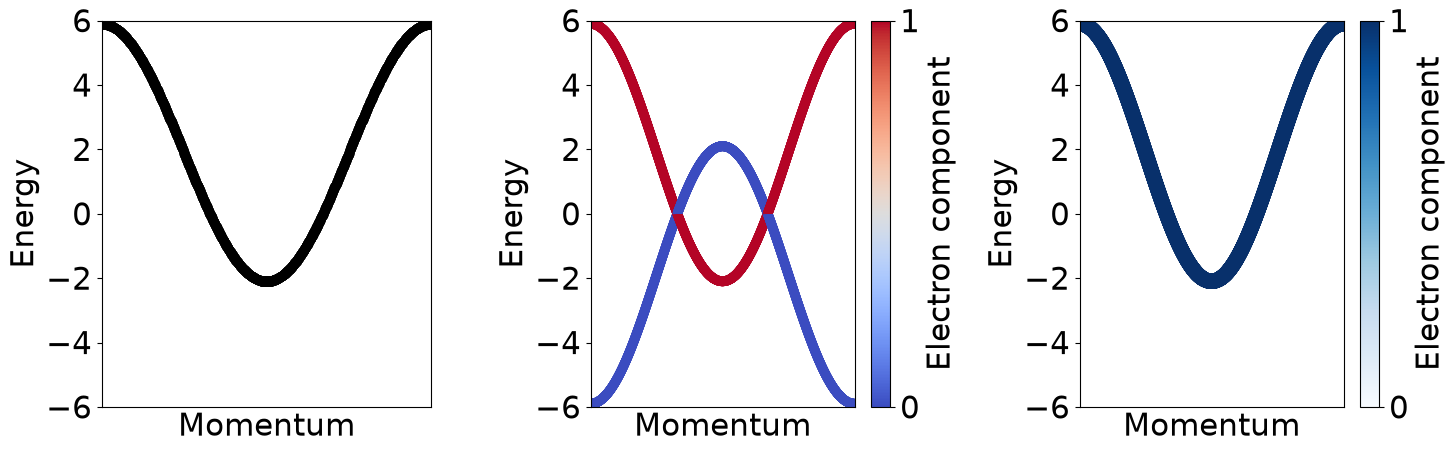

In [2]:
from pyqula import geometry
# as a warm up, let us look at how the bands look like if we added a Nambu spinor
# first, let us see how the band structure looks like
g = geometry.square_lattice() # generate a square lattice
h = g.get_hamiltonian() # generate the Hamiltonian
h.set_filling(0.2,nk=20) # set filling

fig = plt.figure(figsize=(15,5))

# first without Nambu spinor
plt.subplot(1,3,1)
(k,e) = h.get_bands(nk=800) # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) 
plt.xlim([min(k),max(k)]) ; plt.ylim([-6,6])


# now with a Nambu spinor
plt.subplot(1,3,2)
h.setup_nambu_spinor() # setup the nambu spinor
(k,e,c) = h.get_bands(operator="electron",nk=800) # compute band structure, returning the electron-hole flavor
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) # plot
plt.colorbar(label="Electron component",ticks=[0.,1.]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([-6,6])

plt.subplot(1,3,3)
plt.scatter(k,e,c=c,s=100*c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy")
plt.colorbar(label="Electron component",ticks=[0.,1.]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([-6,6]) 
plt.xticks([])

plt.tight_layout()

### Quiz
- Discuss how the bands with a Nambu spinor can be understood in terms of the bands without a Nambu spinor

## Nambu electronic structure with superconductivity (***Reminder***)
Now, let us see the electronic structure in the Nambu basis, in the presence of superconductivity

Once we add an s-wave pairing $\Delta$, the electron block and the hole block get coupled,
$$H_{BdG}=\begin{pmatrix}H_0-\mu & \Delta\\ \Delta^\dagger & -(H_0-\mu)^*\end{pmatrix}$$
and the electron and hole bands, that before were just crossing each other, now anticross. Look at where in the band structure this happens, and at how the electron projection changes.

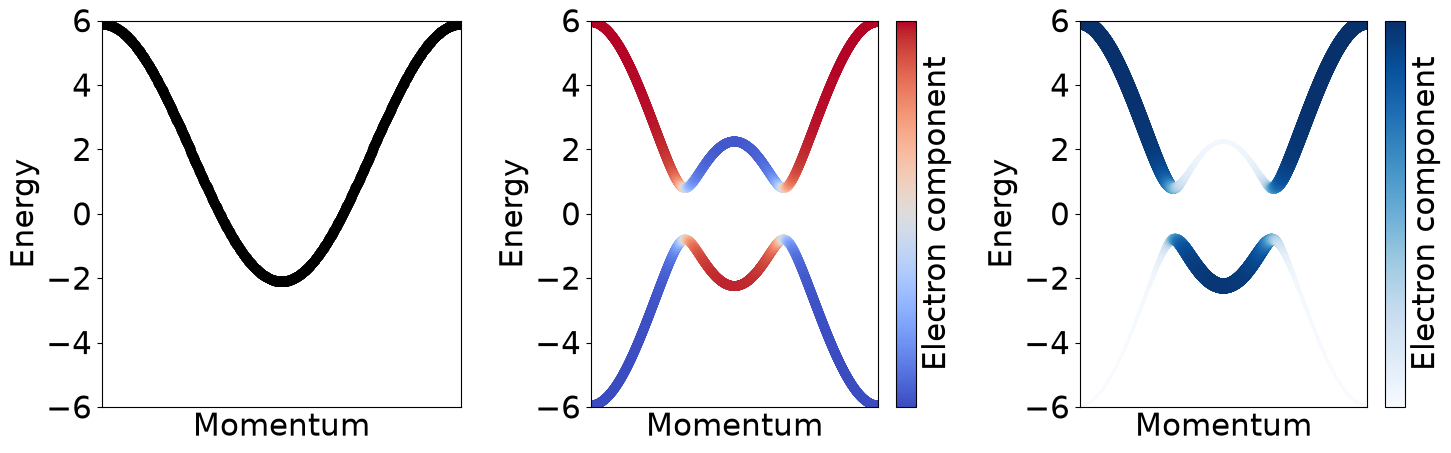

In [3]:
from pyqula import geometry
# as a warm up, let us look at how the bands look like if we added a Nambu spinor
# first, let us see how the band structure looks like
g = geometry.square_lattice() # generate a square lattice
h = g.get_hamiltonian() # generate the Hamiltonian
h.set_filling(0.2,nk=20) # set filling

fig = plt.figure(figsize=(15,5))

# first without Nambu spinor
plt.subplot(1,3,1)
(k,e) = h.get_bands(nk=800) # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) 
plt.xlim([min(k),max(k)]) ; plt.ylim([-6,6])


# now with a Nambu spinor
plt.subplot(1,3,2)
h.setup_nambu_spinor() # setup the nambu spinor
h.add_swave(0.8) # add superconductivity
(k,e,c) = h.get_bands(operator="electron",nk=800) # compute band structure, returning the electron-hole flavor
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) # plot
plt.colorbar(label="Electron component",ticks=[0.,1.]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([-6,6])

plt.subplot(1,3,3)
plt.scatter(k,e,c=c,s=100*c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy")
plt.colorbar(label="Electron component",ticks=[0.,1.]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([-6,6])
plt.xticks([])

plt.tight_layout()

### Quiz
- Change the value of the superconducting order (add_swave), what happens to the gap?
- Discuss why a gap opens when you add superconductivity

## Superconductivity, full spectral function and electron spectral function (***Core***)
Here we will look at the relationship between the Nambu band structure, the full BdG spectral function, and the electron spectral function

Here we compute three things for a chain with superconductivity: the Bogoliubov-de Gennes band structure, the total density of states, and the density of states projected onto the electron part. The point is that the total density of states counts both the electron bands and the hole bands, and remember that the hole bands are a replica that we introduced by hand, whereas the electron density of states only counts the true electronic states, which are the ones that an STM tip couples to.

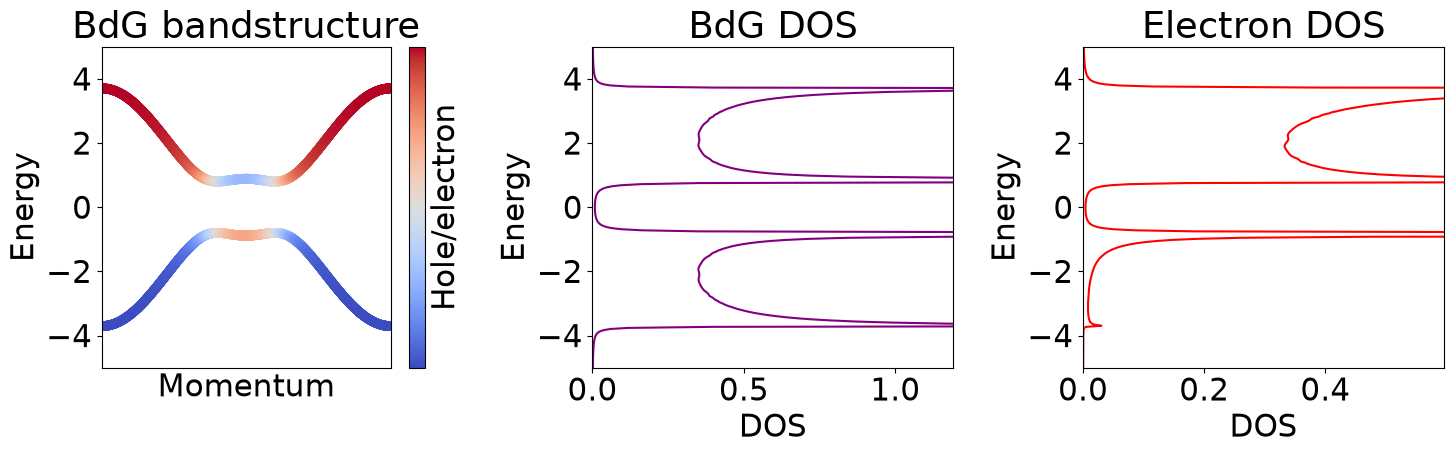

In [4]:
from pyqula import geometry
# as a warm up, let us look at how the bands look like if we added a Nambu spinor
# first, let us see how the band structure looks like
g = geometry.chain() # generate a chain
h = g.get_hamiltonian() # generate the Hamiltonian
filling = 0.2 # filling of the system
h.set_filling(filling,nk=20) # set filling
h.add_swave(0.8) # add superconductivity

fig = plt.figure(figsize=(15,5))
es = np.linspace(-5.0,5.0,300) # energies for the DOS
delta = 1e-2 # energy smearing

# compute BdG bands
plt.subplot(1,3,1)
plt.title("BdG bandstructure")
(k,e,c) = h.get_bands(operator="electron",nk=800) # compute band structure, returning the electron-hole flavor
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) # plot
plt.colorbar(label="Hole/electron",ticks=[0.,1.]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([min(es),max(es)])


plt.subplot(1,3,2)
plt.title("BdG DOS")
e1,d1 = h.get_dos(energies=es,delta=delta,nk=1000)
plt.plot(d1,e1,c="purple")
plt.xlabel("DOS") ; plt.ylabel("Energy")
plt.xlim([0.,3*np.mean(d1)]) ; plt.ylim([min(es),max(es)])

plt.subplot(1,3,3)
plt.title("Electron DOS")
e2,d2 = h.get_dos(energies=es,operator="electron",delta=delta,nk=1000)
plt.plot(d2,e2,c="red")
plt.xlabel("DOS") ; plt.ylabel("Energy")
plt.xlim([0.,3*np.mean(d2)]) ; plt.ylim([min(es),max(es)])


plt.tight_layout()

### Quiz
- Why are the full BdG DOS and the electron DOS different?
- Change the filling of the system, how do the DOS change?
- Remove superconductivity, how are the DOS? Which one is the experimentally observable one?

## The impact of superconductivity in an electronic structure (***Challenge***)
Let us first show how a superconducting order affects an electronic structure. For this, let us change the chemical potential of a lattice, and include spin-singlet superconductivity in the different cases

For each chemical potential we generate the Hamiltonian, we add s-wave superconductivity, and we compute the bands projected onto the electron sector. What is important about an s-wave order is that it couples electrons at $\mathbf k$ with electrons at $-\mathbf k$ regardless of where the Fermi surface is, so wherever the electron and hole bands cross, an anticrossing of size $\approx 2|\Delta|$ opens up. This is very different from a gap coming from the lattice, which only appears at specific fillings.

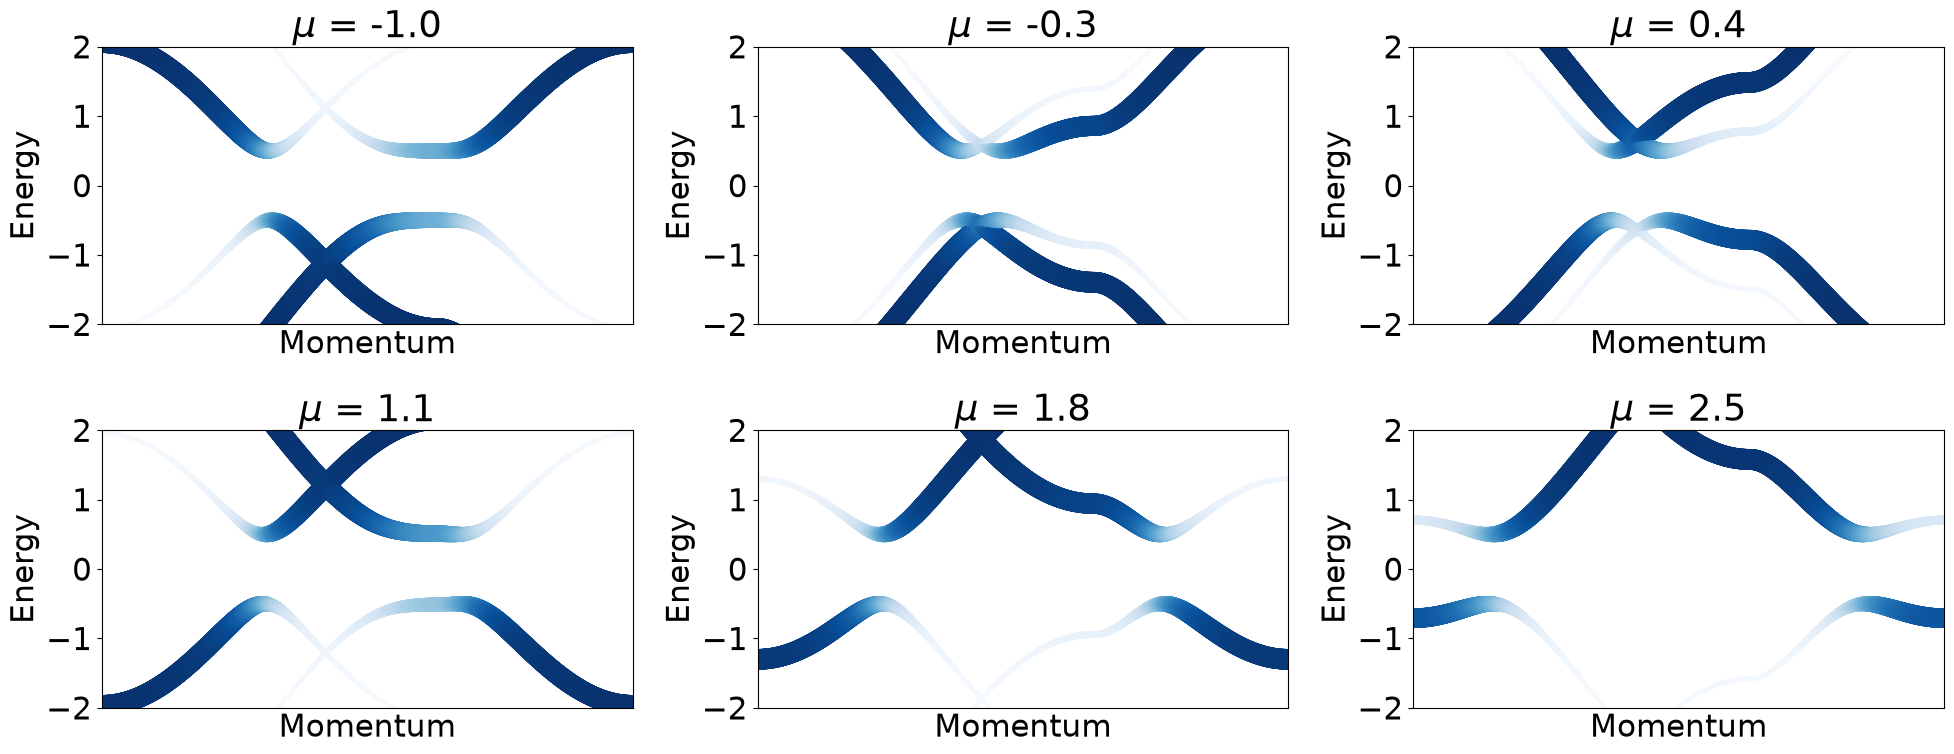

In [5]:
from pyqula import geometry
mus = np.linspace(-1.,2.5,6) # chemical potentials
g = geometry.honeycomb_lattice() # take a honeycomb lattice
iw = 1 # counter
delta = 0.5 # value of the superconducting order
for mu in mus: # loop over local potentials
    h = g.get_hamiltonian() # generate Hamiltonian
    h.add_onsite(mu) # shift chemical potential
    h.add_swave(delta) # add superconductivity 
    plt.subplot(2,len(mus)//2,iw) 
    iw +=1 ; plt.title("$\\mu$ = "+str(np.round(mu,3)))
    (k,e,c) = h.get_bands(operator="electron",kpath=["G","K","M","G"]) # compute band structure
    plt.scatter(k,e,c=c,s=200*c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xlim([min(k),max(k)])
    plt.xticks([]) ; plt.ylim([-2.,2.]) # plot
plt.tight_layout() # adjust

### Quiz
- Switch off the superconducting order. Do you still see a gap at the different chemical potentials?
- Does the gap depend on the chemical potential for finite superconducting order?
- Replace the honeycomb lattice by any other type of lattice. Do you still see a gap opening for different chemical potentials?

## s-wave superconductivity driven by attractive interactions (***Core***)
First, we will show how a superconducting state appears due to attractive interactions

So far we were adding the superconducting order by hand, now we are going to get it from a mean field calculation. We take an attractive Hubbard interaction $-|U| n_{i\uparrow}n_{i\downarrow}$, and the trick is that instead of taking expectation values of the density, as we did for magnetism, we take expectation values between two annihilation operators,
$$-|U| c^\dagger_{i\uparrow}c^\dagger_{i\downarrow}c_{i\downarrow}c_{i\uparrow} \to \Delta_i c^\dagger_{i\uparrow}c^\dagger_{i\downarrow} + \Delta_i^* c_{i\downarrow}c_{i\uparrow},\qquad \Delta_i = -|U|\langle c_{i\downarrow}c_{i\uparrow}\rangle$$
Solving this self-consistently gives a finite $\Delta_i$, which is an s-wave order parameter, and the gap that appears is now driven by the interaction.

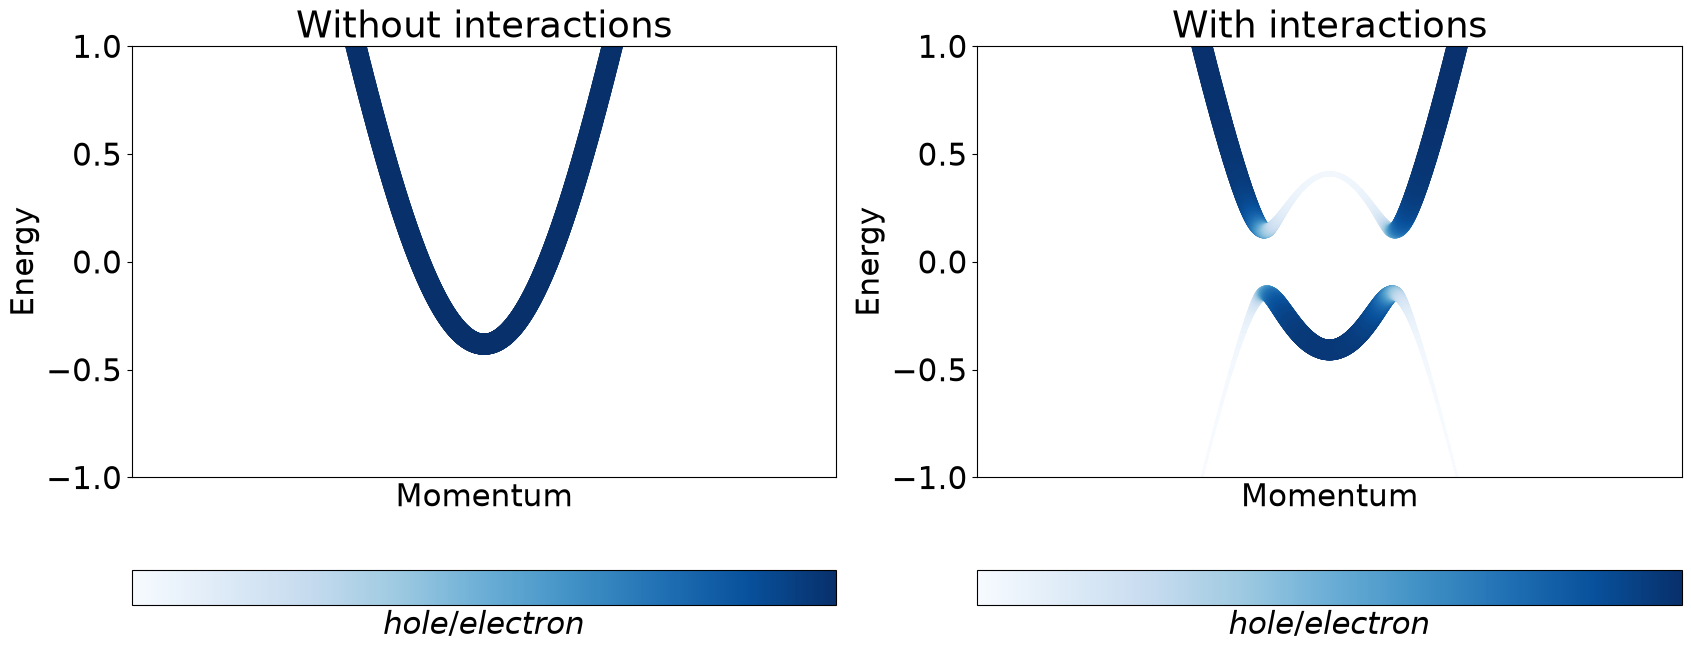

In [6]:
from pyqula import geometry
# now, let us include attractive interactions at the mean-field level
g = geometry.chain() # generate a chain
h = g.get_hamiltonian() # generate the Hamiltonian
h.setup_nambu_spinor() # setup the nambu spinor

def plot_case(hscf):
    (k,e,c) = hscf.get_bands(operator="electron",nk=800) # compute band structure
    plt.scatter(k,e,c=c,s=200*c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.ylim([-1,1]) ; plt.colorbar(label="$hole/electron$",ticks=[],orientation="horizontal")

# first, let us see how the band structure looks like without interactions
plt.subplot(1,2,1) ; plt.title("Without interactions")
filling = 0.2 # set the filling
h.set_filling(filling)
plot_case(h)

# now, let us see how the band structure looks like with interactions
hscf = h.get_mean_field_hamiltonian(U=-1.0,filling=filling,nk=10,mix=0.9,mf="swave")
plt.subplot(1,2,2) ; plt.title("With interactions")
plot_case(hscf)



### Quiz
- Identify the superconducting gap that appear due to interactions
- Increase the value of the attractive interactions. What happens to the superconducting gap?

## Dependence on the strength of the attractive interaction (***Challenge***)
Let us now see how the superconducting order depends on the strength of the interaction

Here we repeat the self-consistent calculation for several values of the attractive interaction, all at the same filling. This is the BCS gap equation at the mean field level, the self-consistent solution of $\Delta = -|U|\langle c_\downarrow c_\uparrow\rangle$ grows with $|U|$, so the stronger the attraction the bigger the gap. What is remarkable about superconductivity is that no matter how small the attractive interaction is, you always get a finite gap.

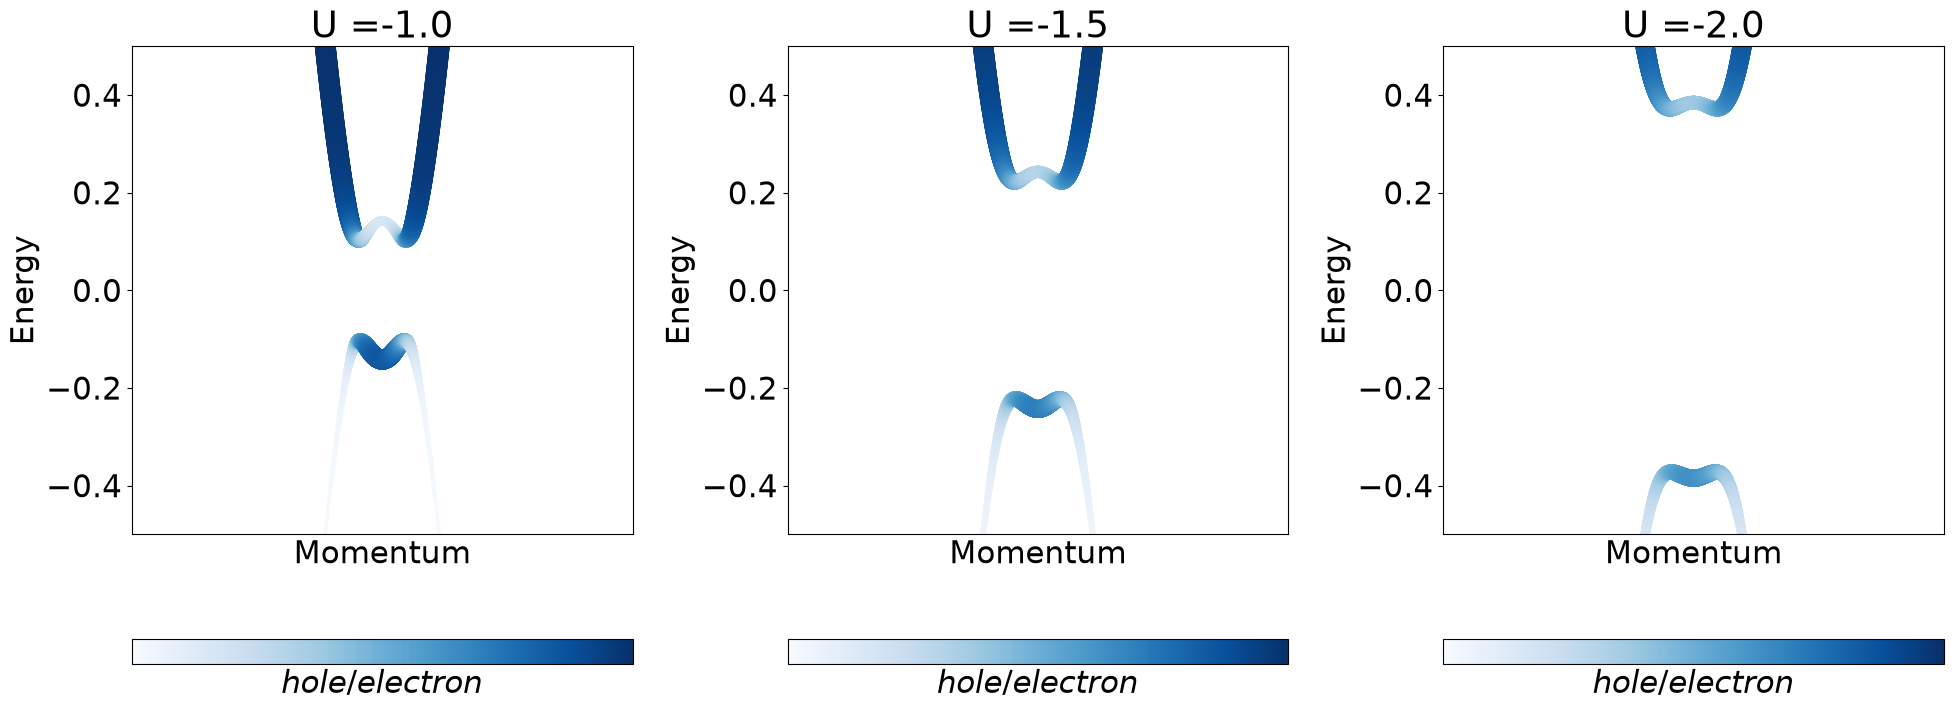

In [7]:
from pyqula import geometry
# We now compare the band structure for different interaction strength
g = geometry.chain() # generate a chain
h = g.get_hamiltonian() # generate the Hamiltonian
h.setup_nambu_spinor() # setup the nambu spinor
Us = [-1.0,-1.5,-2.0]
iu = 0
#h.add_exchange([0.,0.,0.5]) # to add a Zeeman field
for U in Us: # loop over interaction strength
    hscf = h.get_mean_field_hamiltonian(U=U,filling=0.1,nk=100,mix=0.5,mf="swave")
    # first, let us see how the band structure looks like
    (k,e,c) = hscf.get_bands(operator="electron",nk=2000) # compute band structure
    plt.subplot(1,len(Us),iu+1) ; iu += 1
    plt.scatter(k,e,c=c,s=200*c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.ylim([-.5,.5]) ; plt.title("U ="+str(U)) 
    plt.colorbar(label="$hole/electron$",ticks=[],orientation="horizontal")
    
plt.tight_layout()

### Quiz
- Perform the selfconsistent calculation above including an external Zeeman field. Does the superconducting gap become bigger or smaller? This effect is known as paramagnetic depairing.

## Unconventional singlet superconducting orders (***Challenge***)
In the example above we considered the simplest superconducting case, an s-wave superconductor. Let us now address other types of superconducting order parameters

What we plot here is the momentum dependence of the superconducting order $\Delta(\mathbf k)$ for different symmetries. The s-wave order has no momentum dependence at all, the $d_{x^2-y^2}$ order goes as $\cos k_x-\cos k_y$ and changes sign as you go around $\Gamma$, and the extended s-wave order goes as $\cos k_x+\cos k_y$. What you should keep in mind is that the pairing has to be antisymmetric when you exchange the two electrons, so a spin singlet, which is antisymmetric in spin, needs an order parameter that is even in momentum, $\Delta(-\mathbf k)=\Delta(\mathbf k)$.

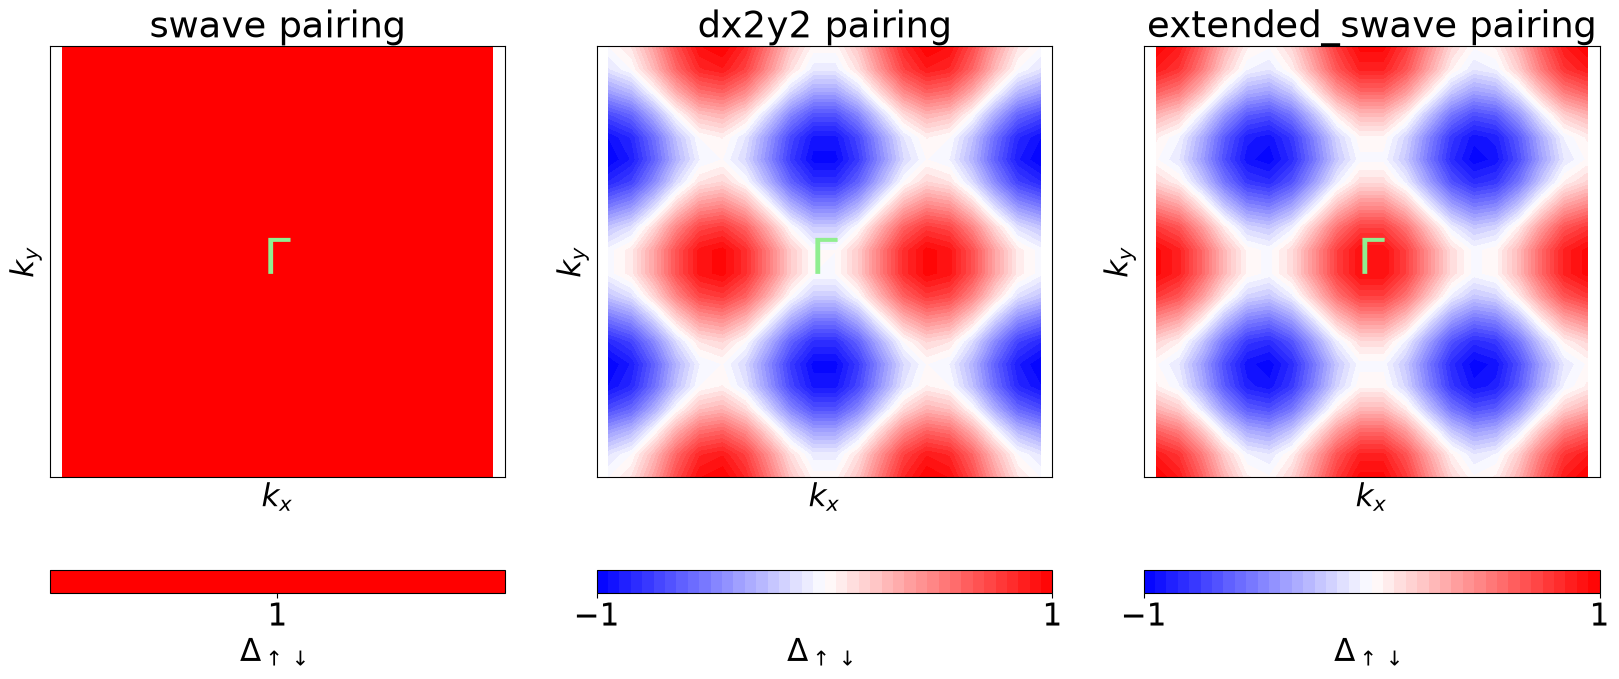

In [8]:
from pyqula import geometry
g = geometry.square_lattice() # generate a square lattice

# define a function to return pairing in reciprocal space
def deltak(mode): # function to extract the pairing from a geometry
    h = g.get_hamiltonian() # generate Hamiltonian
    h.add_pairing(mode=mode,delta=0.2) # add pairing
    nk = 20 # number of k-points
    ks = np.linspace(-1.,1.,nk)
    ds = [] # empty list
    for kx in ks:
        for ky in ks: ds.append(h.get_hk_gen()([kx,ky])[0,2]) # extract pairing from the Hamiltonian matrix
    ds = ds/np.max(np.abs(ds)) ; ds = ds.real # make the order parameter real
    ds = ds.reshape((nk,nk)) ; ds = ds.real/np.max(np.abs(ds)) # normalize
    plt.contourf(ks,ks,ds,vmin=-1,vmax=1.,levels=40,cmap="bwr") ; plt.axis("equal") # make the plot
    plt.text(0., 0., "$\\Gamma$", fontsize=35,ha="center",va="center",c="lightgreen") # plot the Gamma point
    plt.colorbar(ticks=[-1,1],label="$\\Delta_{\\uparrow\\downarrow}$",orientation = 'horizontal')
    plt.title(mode+" pairing") ; plt.xlabel("$k_x$") ; plt.ylabel("$k_y$") ; plt.xticks([]) ; plt.yticks([])

ps = ["swave","dx2y2","extended_swave"]
ip = 1
for p in ps: # plot all the pairings
    plt.subplot(1,len(ps),ip) ; ip+=1 
    deltak(p)


### Quiz
- Discuss how you can see from the plots above that those pairings correspond to a spin singlet state from symmetry considerations
- (Advanced) Does the extended s-wave order lead to a fully gapped superconductor?

## The impact of a spin splitting in an electronic structure (***Reminder***)
Let us first recall what having a spin splitting looks like

Here we take a chain and we add an exchange field $\mathbf J=(0,0,J)$, which enters the Hamiltonian as a Zeeman-like term $-J s_z$. The single band splits into one band for spin up, $E_{\mathbf k,\uparrow}=E(\mathbf k)-J$, and one for spin down, $E_{\mathbf k,\downarrow}=E(\mathbf k)+J$, so the two spin species are rigidly shifted in opposite directions.

(-4.0, 4.0)

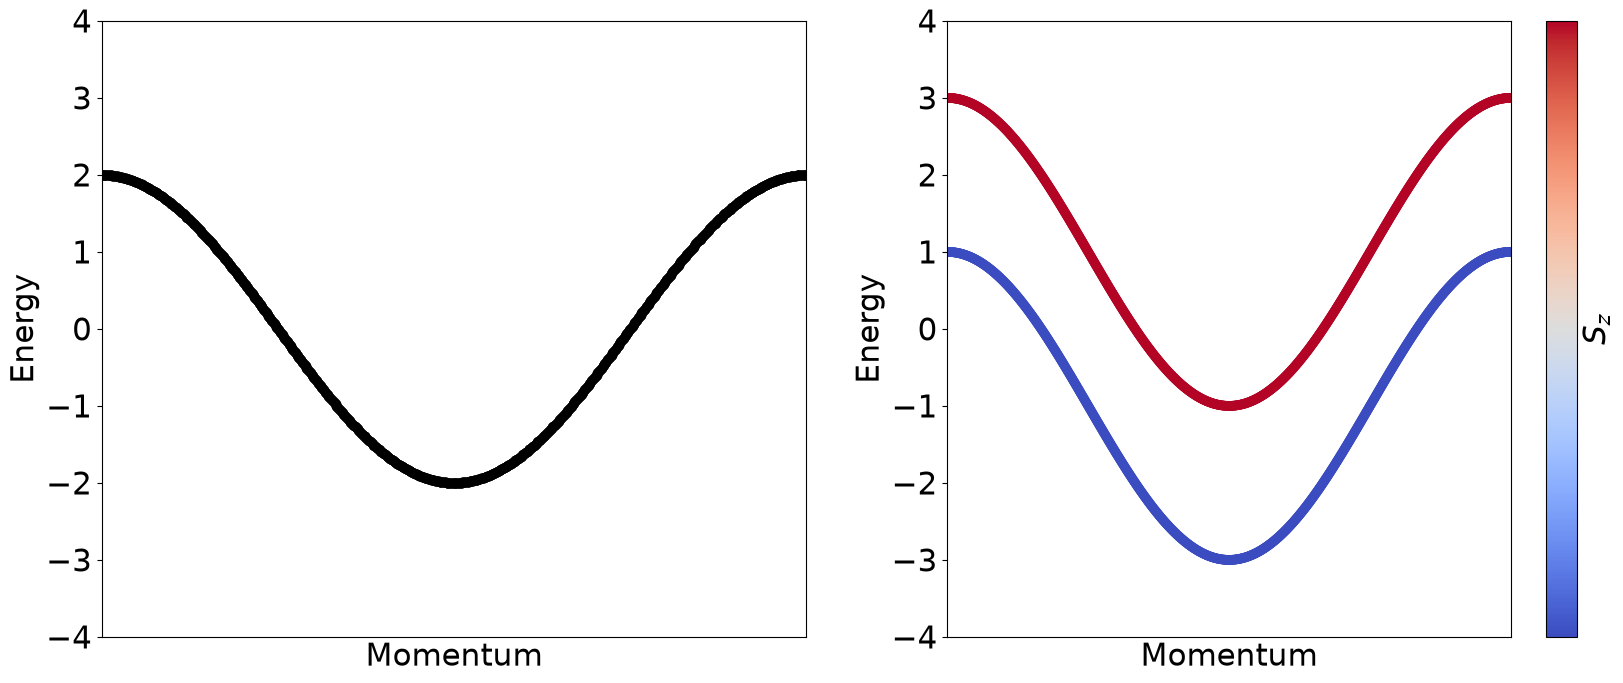

In [9]:
from pyqula import geometry
g = geometry.chain() # generate geometry
h = g.get_hamiltonian() # generate the Hamiltonian

# first without exchange
plt.subplot(1,2,1)
(k,e) = h.get_bands(nk=800) # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) 
plt.xlim([min(k),max(k)]) ; plt.ylim([-4,4])


# now with a Nambu spinor
plt.subplot(1,2,2)
h.add_exchange([0.,0.,1.0]) # add exchange field
(k,e,c) = h.get_bands(operator="sz",nk=800) # compute band structure, returning the electron-hole flavor
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) # plot
plt.colorbar(label="$S_z$",ticks=[]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([-4,4])

### Quiz
- Change the value of the exchange in the Hamiltonian, what happens to the splitting between up and down spins?
- Does the band structure on the right break time-reversal symmetry? How can you see that?

## A spin triplet superconductor (***Core***)
We are now going to compute a spin triplet superconductor, and show that it has edge modes

The way we build a spin triplet superconductor is by adding a p-wave pairing, $\Delta(k)\propto\sin k$, which is odd in $k$ as a triplet order must be, and here we do it in a chain with a large exchange field, so that effectively the electrons are spinless, which is the Kitaev chain. We compute the band structure of the infinite chain, and then the spectrum of a finite chain with the same pairing. The bulk is fully gapped, and the interesting thing is what appears in the finite system that does not exist in the infinite one: this is a topological superconductor, and those states are its Majorana modes.

(-3.0, 3.0)

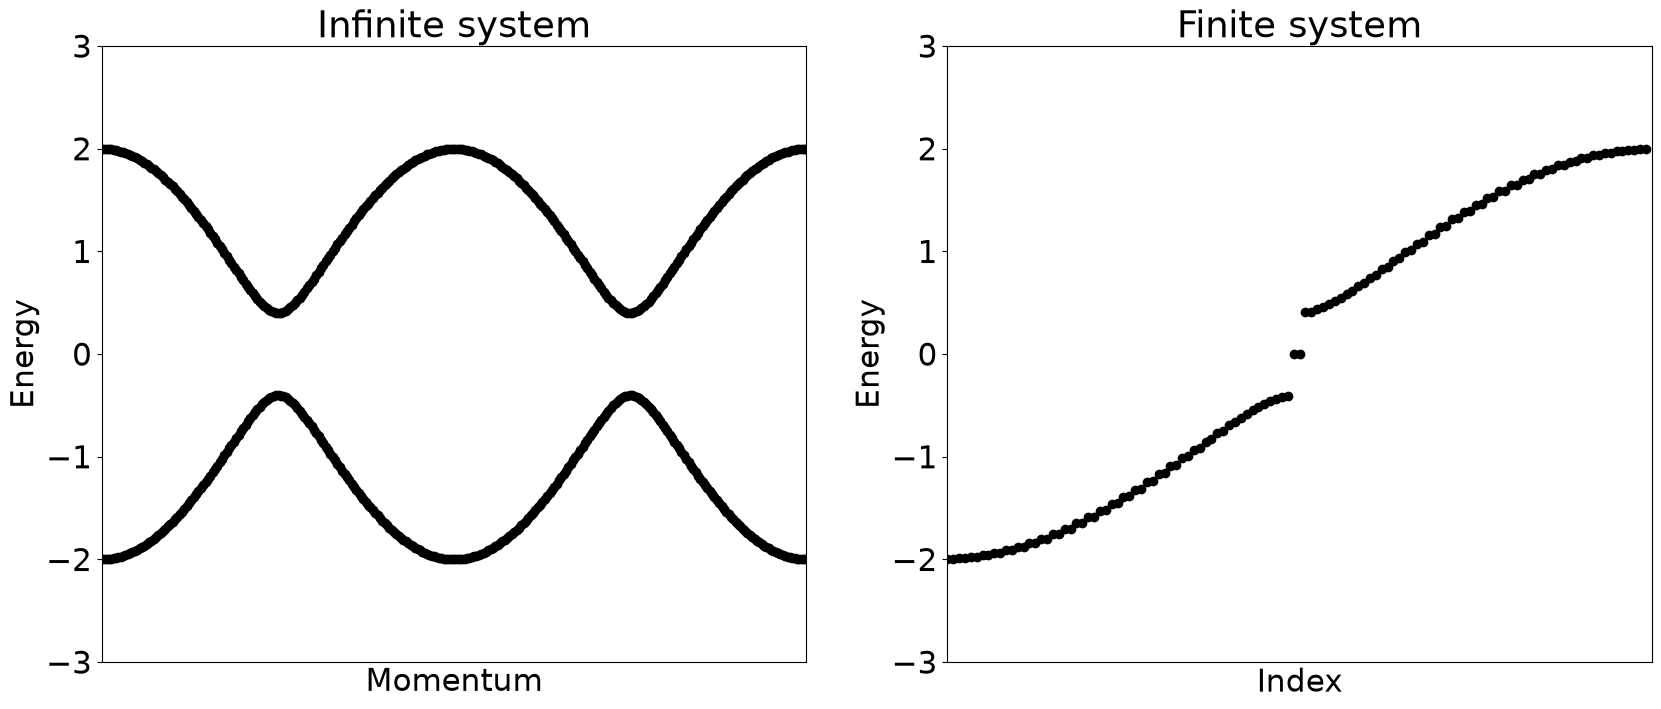

In [10]:
from pyqula import geometry

def get_kitaev_model(g): # transform a geometry into the Kitaev model
    h = g.get_hamiltonian() # generate a Hamiltonian
    h.add_onsite(4.0) ; h.add_exchange([0.,0.,4.]) # spinless electron gas
    delta = 0.2 # strength of the superconducting order
    h.add_pairing(mode="pwave",delta=delta,d=[1.,0.,0.]) # add p-wave SC order
    return h

# first the bulk
gb = geometry.chain()
plt.subplot(1,2,1)
plt.title("Infinite system")
hb = get_kitaev_model(gb) # generate kitaev model
k,e = hb.get_bands(nk=300)
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) 
plt.xlim([min(k),max(k)]) ; plt.ylim([-3,3])

# now the finite system
plt.subplot(1,2,2)
plt.title("Finite system")
L = 60 # length of the finite system
gf = gb.get_supercell(L) ; gf.dimensionality = 0 # make a finite system
hf = get_kitaev_model(gf) # generate kitaev model
ind,e = hf.get_bands()
e = e[np.abs(e)<3.] # only low energy
plt.scatter(range(len(e)),e,c="black") ; plt.xlabel("Index") ; plt.ylabel("Energy") ; plt.xticks([]) 
plt.xlim([0,len(e)]) 
plt.ylim([-3,3])



### Quiz
- Change the value of the superconducting order "delta", how does the electronic structure change?
- Why are there zero modes for a finite system but not for an infinite system?
- Decrease the length of the finite system L, what happens to the zero modes?

## Majorana modes in a spin triplet superconductor (***Challenge***)
Let us now analyze the zero modes of a topological superconductor

Here we take a long Kitaev chain and we compute the local density of states at several sites, right at the edge, a bit further in, and in the bulk. If the zero mode is a true edge mode you should see a peak at $E=0$ at the edge, that becomes smaller as you move away from it, and that is gone once you are in the bulk, where only the gapped states remain.

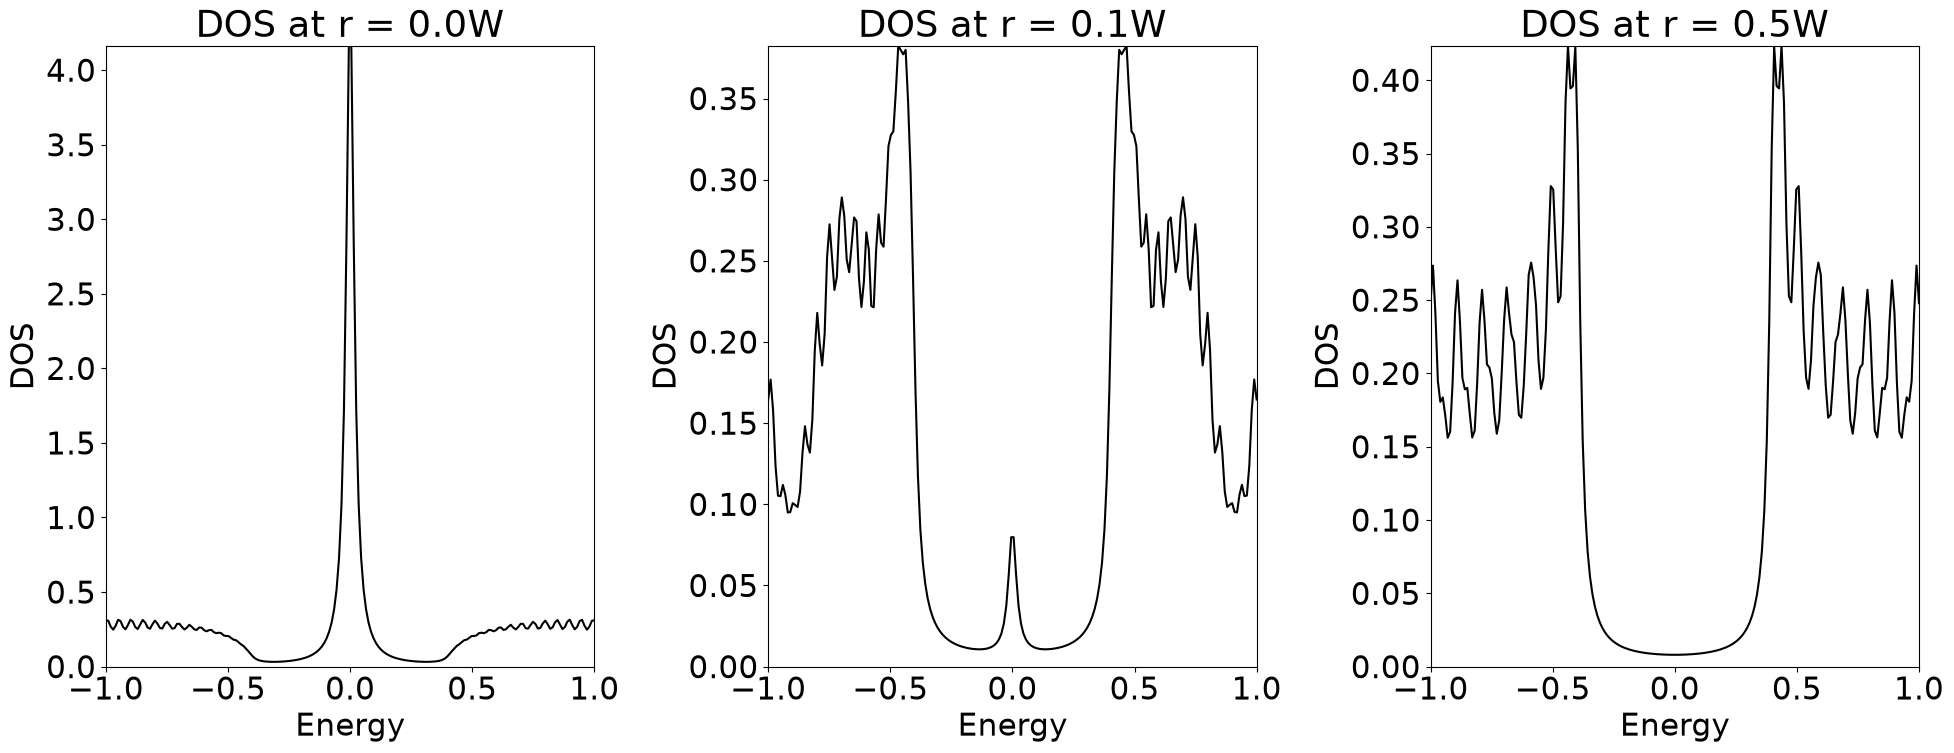

In [11]:
from pyqula import geometry

def get_kitaev_model(g): # transform a geometry into the Kitaev model
    h = g.get_hamiltonian() # generate a Hamiltonian
    h.add_onsite(4.0) ; h.add_exchange([0.,0.,4.]) # spinless electron gas
    delta = 0.2 # strength of the superconducting order
    h.add_pairing(mode="pwave",delta=delta,d=[1.,0.,0.]) # add p-wave SC order
    return h

# generate the finite system
L = 100 # length of the finite system
gb = geometry.chain() # bulk geometry
gf = gb.get_supercell(L) ; gf.dimensionality = 0 # make a finite system
h = get_kitaev_model(gf) # generate kitaev model

inds = [0,L//10,L//2]

energies= np.linspace(-1.,1.,200)
ii = 0
for ind in inds: # loop over indexes
    plt.subplot(1,len(inds),ii+1) ; ii += 1 
    P = h.get_operator("site",index=ind)*h.get_operator("electron") # electron part of the spectral function
    (es,ds) = h.get_dos(operator=P,energies=energies,delta=2e-2)
    plt.plot(es,ds,c="black") ; plt.ylim([0,max(ds)])
    plt.title("DOS at r = "+str(round(ind/L,2))+"W")
    plt.xlabel("Energy") ; plt.ylabel("DOS") ; plt.xlim([min(es),max(es)])
plt.tight_layout()

### Quiz
- Decrease the length L of the finite chain, what happens to the spectra and why?

## Emergence of Majorana modes as a function of the size of the superconductor (***Core***)
We will now see how the emergence of Majorana zero modes is associated to the length of the topological superconductor

Now we compute the density of states at the edge and in the bulk for chains of increasing length $L$, and we plot everything together, with the length in the x axis and the energy in the y axis. The two Majorana modes at the two ends of the chain have a finite localization length $\xi$, and when the chain is short their wave functions overlap and they hybridize into an ordinary fermionic level, split away from zero energy by $\delta E\sim e^{-L/\xi}$. Only when $L\gg\xi$ the two modes decouple and get pinned at $E=0$.

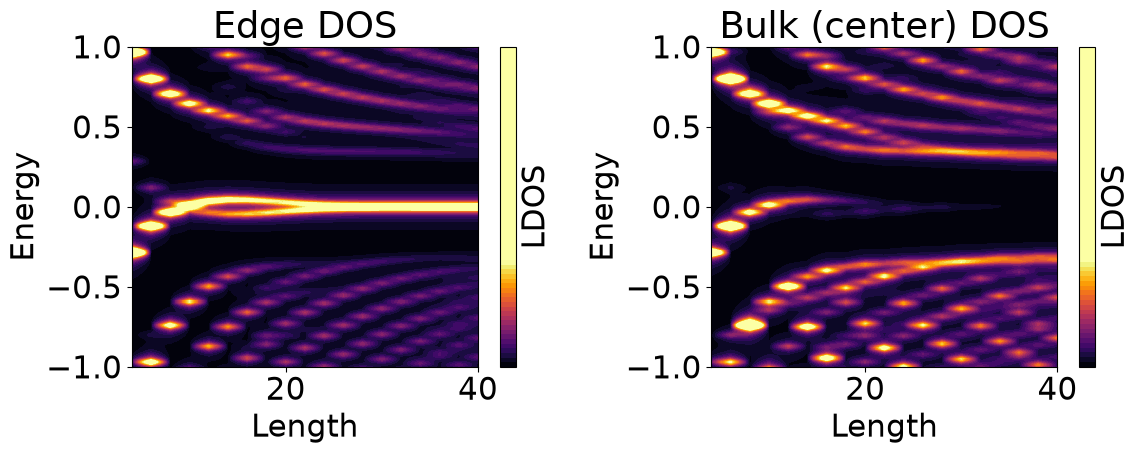

In [12]:
from pyqula import geometry

def get_kitaev_model(L=4,mu=.0,Delta=0.2): # transform a geometry into the Kitaev model
    g = geometry.chain() # bulk geometry
    g = g.get_supercell(L) ; g.dimensionality = 0 # make a finite system
    h = g.get_hamiltonian() # generate a Hamiltonian
    h.add_onsite(4.0) ; h.add_exchange([0.,0.,4.]) # spinless electron gas
    h.add_onsite(mu) # chemical potential
    h.add_pairing(mode="pwave",delta=Delta,d=[1.,1.,0.]) # add p-wave SC order
    return h

# generate the finite system
energies= np.linspace(-1.,1.,200)
Ls = range(4,42,2)
dedge,dbulk = [],[] # edge and bulk DOS
for L in Ls: # loop over lengths
    Delta = 0.1 # strength of superconducting order
    mu = 0.3 # chemical potential
    h = get_kitaev_model(L=L,Delta=Delta,mu=mu) # generate kitaev model
    Pedge = h.get_operator("site",index=0)*h.get_operator("electron") # electron part of the spectral function
    Pbulk = h.get_operator("site",index=L//2)*h.get_operator("electron") # electron part of the spectral function
    dedge.append(h.get_dos(operator=Pedge,energies=energies,delta=2e-2)[1]) # edge DOS
    dbulk.append(h.get_dos(operator=Pbulk,energies=energies,delta=2e-2)[1]) # bulk DOS
dedge = np.array(dedge).T # as array
dbulk = np.array(dbulk).T # as array

fig = plt.figure(figsize=(12,5))
plt.subplot(1,2,1) ; plt.title("Edge DOS")
plt.contourf(Ls,energies,dedge,levels=80,cmap="inferno",vmin=0.,vmax=np.max(dedge)/3.)
plt.xlabel("Length") ; plt.ylabel("Energy")
plt.colorbar(ticks=[],label="LDOS")


plt.subplot(1,2,2) ; plt.title("Bulk (center) DOS")
plt.contourf(Ls,energies,dbulk,levels=80,cmap="inferno",vmin=0.,vmax=np.max(dbulk)/3.)
plt.colorbar(ticks=[],label="LDOS")
plt.xlabel("Length") ; plt.ylabel("Energy")

plt.tight_layout()

### Quiz
- Why do the zero modes appear in the edge as the system gets bigger?
- Why do the zero modes disappear from the bulk as the system gets bigger?
- Increase the value of topological superconducting gap Delta, what happens and why?
- Decrease the value of topological superconducting gap Delta, what happens and why?
- Change the chemical potential mu, what happens and why?

## Interaction-induced spin-triplet superconductivity (***Challenge***)
We will now see that even in systems breaking time-reversal symmetry, superconductivity can emerge

Before, the p-wave order was put by hand, now we are going to get it from interactions. We take a triangular lattice, we add a large exchange field to make the system magnetic, and we add an attractive first neighbor interaction that we solve at the mean field level in the pairing channel. The exchange field splits spin up from spin down, and you should think about what this implies for the pairings that can appear. We also compute the Chern number, to check whether the gap that opens is topological.

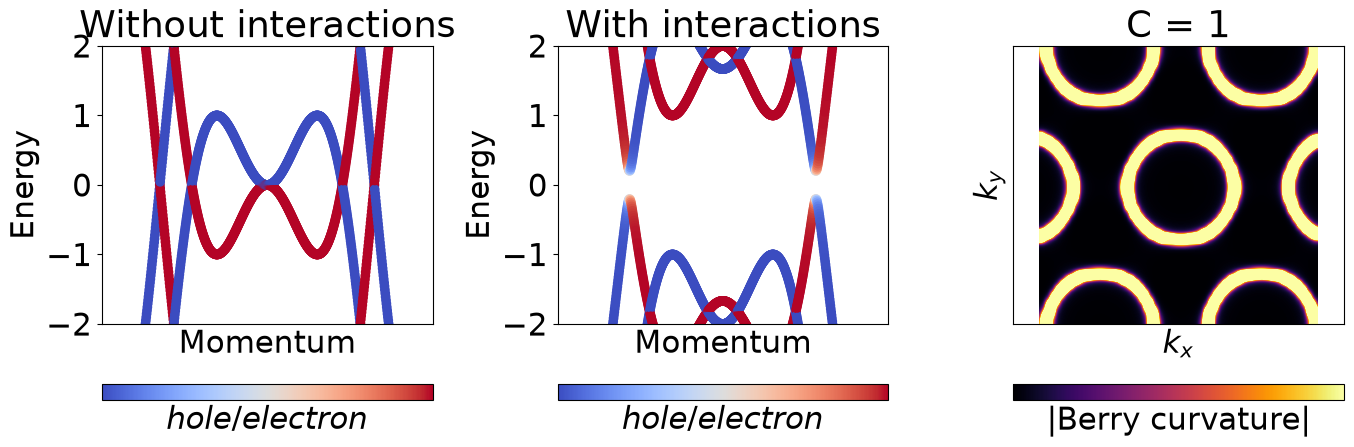

In [13]:
from pyqula import geometry
# now, let us include attractive interactions at the mean-field level
g = geometry.triangular_lattice() # generate a triangular lattice
h = g.get_hamiltonian() # generate the Hamiltonian
h.add_exchange([0.,0.,-2.]) # break time-reversal symmetry with an exchange field
h.setup_nambu_spinor() # setup the nambu spinor

def plot_case(hscf):
    (k,e,c) = hscf.get_bands(operator="electron",nk=800) # compute band structure
    plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.ylim([-2,2]) ; plt.colorbar(label="$hole/electron$",ticks=[],orientation="horizontal")

fig = plt.figure(figsize=(14,5))
  

# first, let us see how the band structure looks like without interactions
plt.subplot(1,3,1) ; plt.title("Without interactions")
plot_case(h)

# now, let us see how the band structure looks like with interactions
hscf = h.get_mean_field_hamiltonian(V1=-1.,filling=0.3,mix=0.3,mf="random")
plt.subplot(1,3,2) ; plt.title("With interactions")
plot_case(hscf)

plt.subplot(1,3,3) ; plt.title("Chern number")
nk = 60 # number of kpoints
c = hscf.get_chern(nk=nk) # compute Chern number
# now let us compute the Berry curvature in 2D
(kx,ky,omega) = hscf.get_berry_curvature(nk=nk) # compute Berry curvature
plt.title("C = "+str(int(round(c))))
omega2d = np.array(omega).reshape((nk,nk)) # reshape as a 2d array
plt.imshow(np.abs(omega2d),interpolation="bicubic",cmap="inferno",vmax=10,vmin=0.) # plot
plt.axis("equal") ; plt.colorbar(label="|Berry curvature|",orientation="horizontal",ticks=[])
plt.xticks([]) ; plt.yticks([]) ; plt.xlabel("$k_x$") ; plt.ylabel("$k_y$")

plt.tight_layout()

#### In the lab
- Spin triplet superconductivity has been observed in twisted graphene trilayers under an external magnetic field
https://www.nature.com/articles/s41586-021-03685-y

### Quiz
- How do we know that this is spin-triplet superconductivity?
- Remove the exchange field. Can you get spin singlet superconductivity? Explain why
- Which of the two orders is topologically non-trivial?

## Topological modes in interaction-driven spin triplet superconductors (***Challenge***)
Let us now see that the interaction-induced topological superconductor above has topological modes

Here we take the very same mean field solution as before, we cut it into a ribbon, and we compute the band structure together with the local density of states at zero energy. Since the bulk has a finite Chern number, there must be a consequence once the system has edges, and that consequence is states crossing the gap that live at the edges. You can check this directly in the plots.

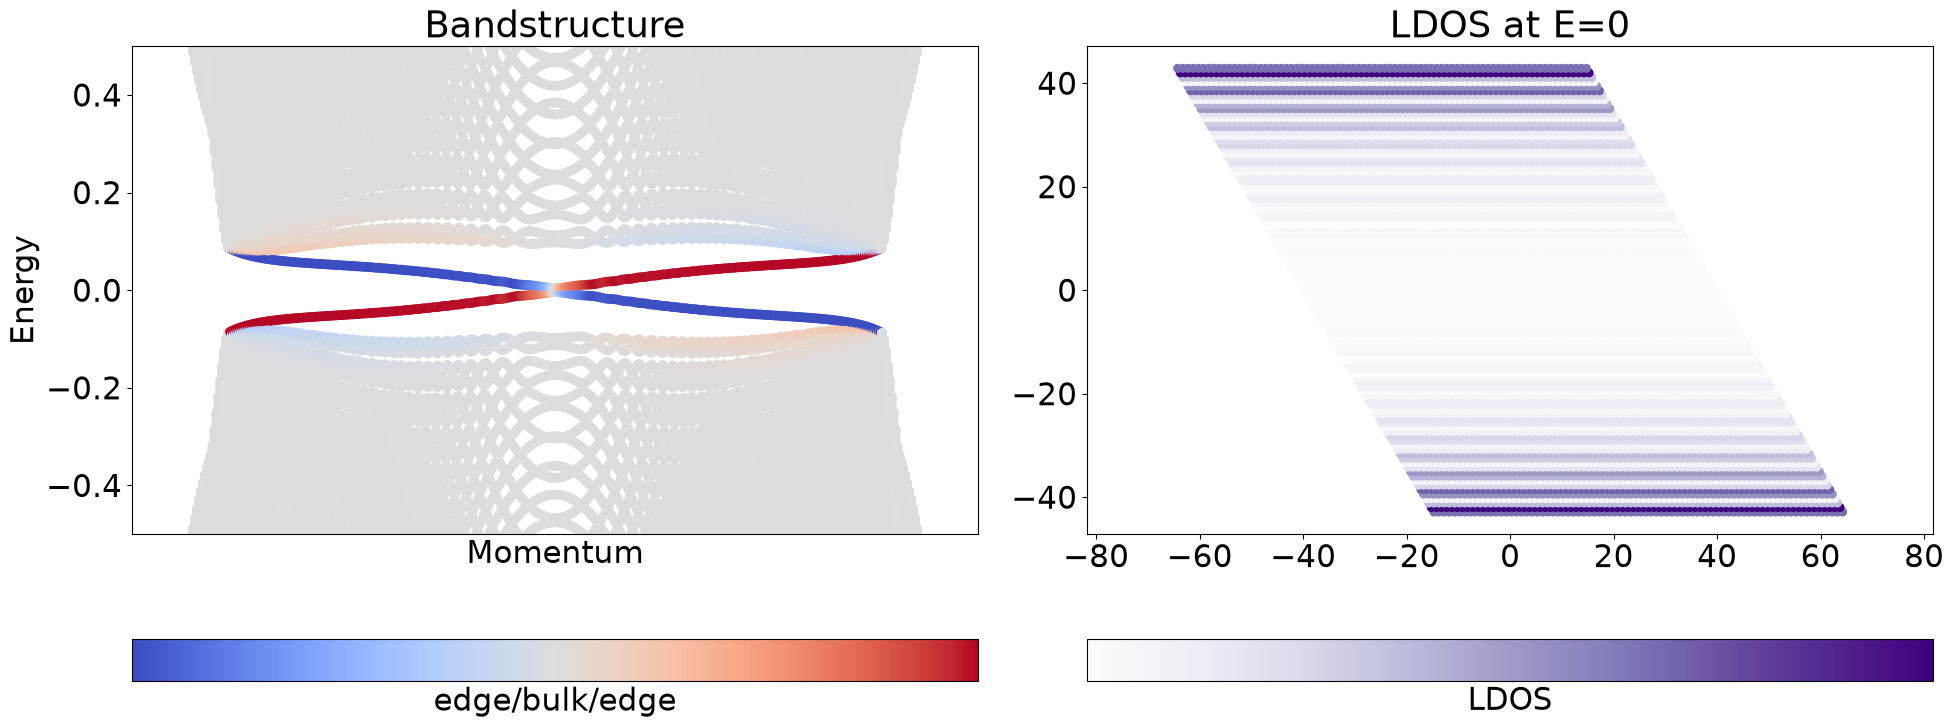

In [14]:
from pyqula import geometry, ribbon

g = geometry.triangular_lattice() # generate a triangular lattice
h = g.get_hamiltonian() # generate the Hamiltonian
h.add_exchange([0.,0.,1.]) # break time-reversal symmetry with an exchange field
h.setup_nambu_spinor() # setup the nambu spinor
h = h.get_mean_field_hamiltonian(V1=-1.,filling=0.3,mix=0.5,mf="random")

# now plot electronic structure in a ribbon
plt.subplot(1,2,1) ; plt.title("Bandstructure") # first the bands
hr = ribbon.bulk2ribbon(h,n=100) # create a ribbon from a bulk Hamiltonian
(k,e,c) = hr.get_bands(operator="yposition",kpath=["X","G","X"]) # plot the bands highlighting the position
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-.5,.5])
plt.colorbar(label="edge/bulk/edge",ticks=[],orientation="horizontal")

plt.subplot(1,2,2) ; plt.title("LDOS at E=0") # now the LDOS
(x,y,d) = hr.get_ldos(energy=0.0,nrep=80,delta=1e-2,nk=50) # compute the local density of states
plt.scatter(x,y,c=d,s=30,cmap="Purples") ; plt.axis("equal") 
plt.colorbar(label="LDOS",ticks=[],orientation="horizontal")

plt.tight_layout() # adjust subplots

### Quiz
- Remove the external exchange field. What happens to the electronic structure of the ribbon?
- Put the exchange field in a different direction. What happens to the electronic structure and why?

## Trivial and topological superconducting order parameters, bulk spectra (***Core***)
Let us now see that a gapped superconducting state can be trivial or topological.

Here we take a triangular lattice and we add two different pairings, an s-wave order and a chiral p-wave order $\Delta(\mathbf k)\propto k_x+ik_y$, and we compute the bands and the Chern number for each one. What is surprising is that the two electronic structures look very similar, both have a gap everywhere in the Brillouin zone, and yet the two gaps are topologically different: the s-wave gap has Chern number zero, whereas the chiral p-wave gap, whose phase winds once around the Fermi surface, has a finite Chern number.

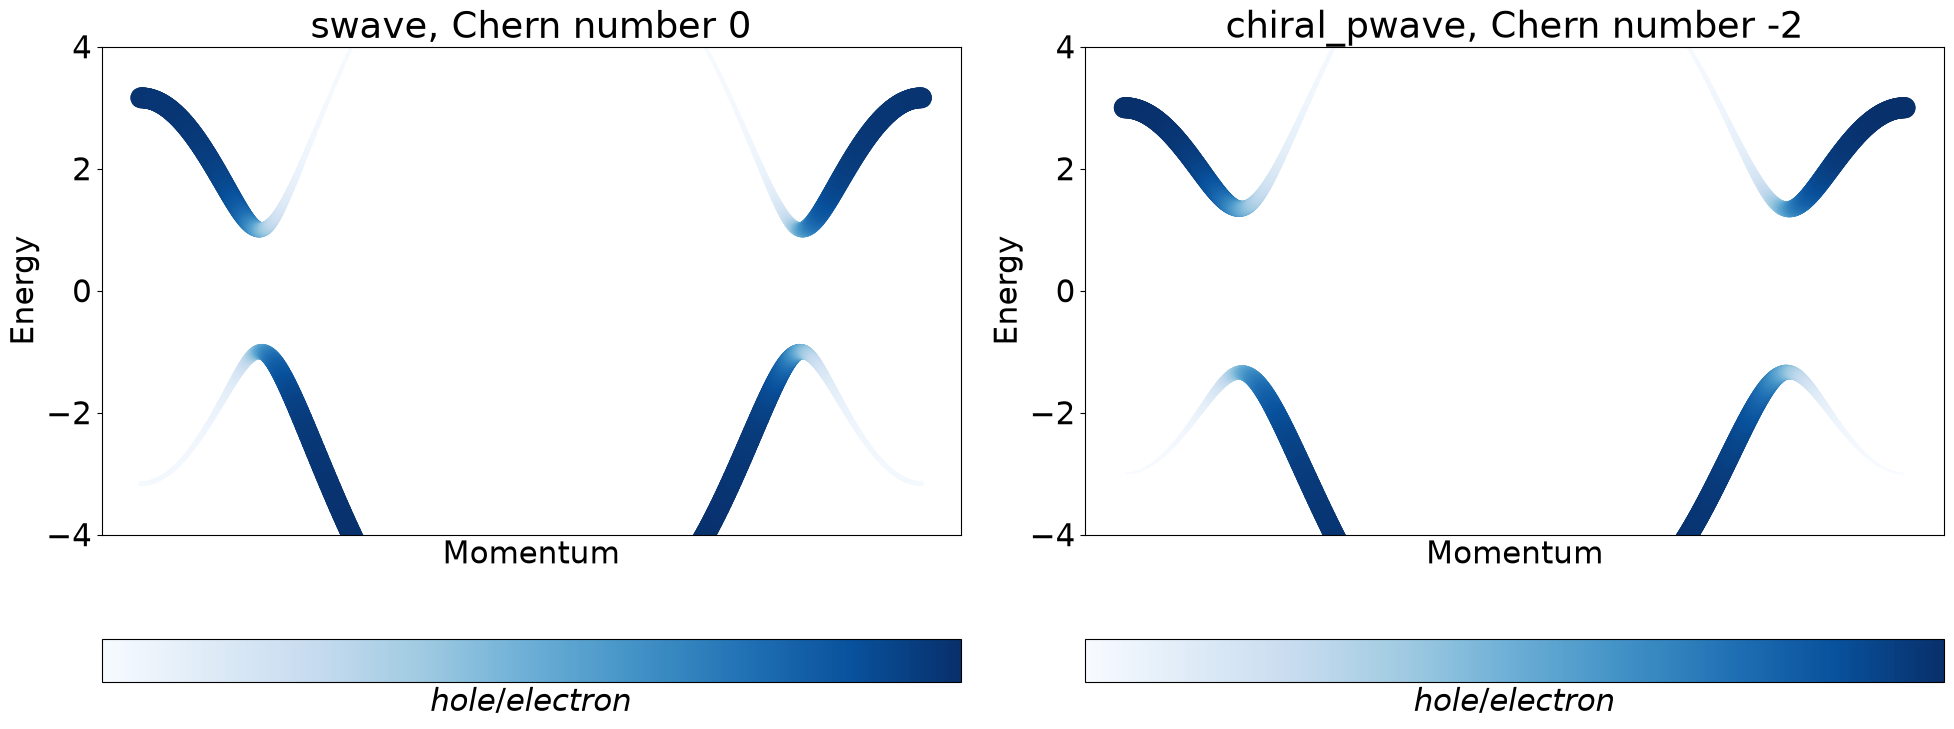

In [15]:
from pyqula import geometry
g = geometry.triangular_lattice() # generate a triangular lattice

def plot_case(name,delta): 
    h = g.get_hamiltonian() ; h.add_onsite(-3.0) # generate Hamiltonian
    h.add_pairing(mode=name,delta=delta) # add pairing
    (k,e,c) = h.get_bands(operator="electron",kpath=["G","K","M","G"]) # compute bands
    plt.scatter(k,e,c=c,s=200*c,cmap="Blues") ; plt.xlabel("Momentum") 
    plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-4,4]) # plot
    plt.colorbar(label="$hole/electron$",ticks=[],orientation="horizontal")
    chern = h.get_chern()
    plt.title(name+", Chern number "+str(int(chern)))

# first s-wave
plt.subplot(1,2,1) 
plot_case("swave",1.0)

# now chiral pwave
plt.subplot(1,2,2) 
plot_case("chiral_pwave",0.4)
    
plt.tight_layout()

### Quiz
- Add both swave and pwave superconducting order, what happens to the electronic band structure?
- Change the chemical potential. How does the chiral pwave superconducting order change? Explain why

## Trivial and topological superconducting order parameters, edge spectra (***Core***)
Let us now see that a gapped topological state can be trivial or topological, leading the presence or absence of edge states

Now we take a ribbon of the same triangular lattice with either the s-wave or the chiral p-wave order, and we look at the band structure. The bulk-boundary correspondence that we saw for Chern insulators in session 3 applies in the same way here: a trivial gap has nothing at the edge, whereas a topological gap has chiral states crossing it, localized at the two edges.

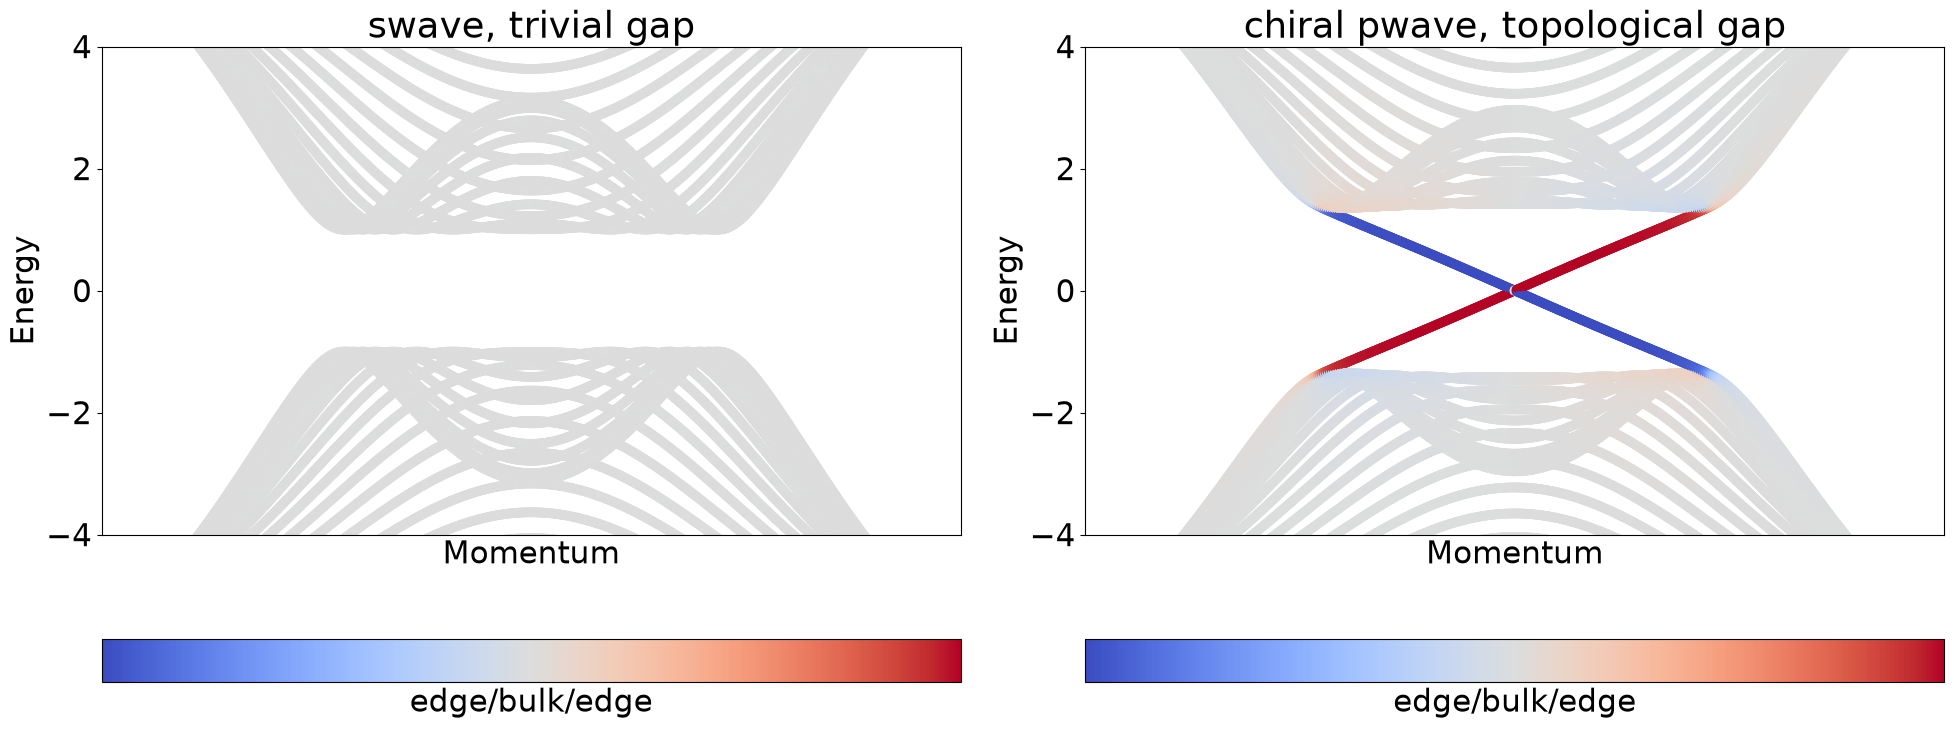

In [16]:
from pyqula import geometry, ribbon
g = geometry.triangular_lattice() # generate a triangular lattice
g = ribbon.bulk2ribbon(g,n=20) # create a ribbon from a bulk Hamiltonian

def plot_case(name,delta): 
    h = g.get_hamiltonian() ; h.add_onsite(-3.0) # generate Hamiltonian
    h.add_pairing(mode=name,delta=delta) # add pairing
    (k,e,c) = h.get_bands(operator="yposition",kpath=["X","G","X"]) # plot the bands highlighting the position
    plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-4,4])
    plt.colorbar(label="edge/bulk/edge",ticks=[],orientation="horizontal")

# first s-wave
plt.subplot(1,2,1) ; plt.title("swave, trivial gap")
plot_case("swave",1.0)

# now chiral pwave
plt.subplot(1,2,2) ; plt.title("chiral pwave, topological gap")
plot_case("chiral_pwave",0.4)
    
plt.tight_layout()

### Quiz
- Include both swave and chiral pwave orders. What happens to the electronic structure?
- Change the chemical potential. How does the electronic structure change?

## Gapped and nodal superconducting orders (***Core***)
Let us now discuss different superconducting orders in the triangular lattice, in particular focusing on gapped s-wave order and nodal f-wave order

An s-wave order is fully gapped, meaning that it opens up a gap everywhere in the Brillouin zone. The f-wave order is different, it is odd under $\mathbf k\to-\mathbf k$, so it has to change sign as you go around the Fermi surface, and to change sign it has to go through zero somewhere. At those points, the nodes, no gap opens and the quasiparticles remain gapless, so this is what is called a nodal superconductor.

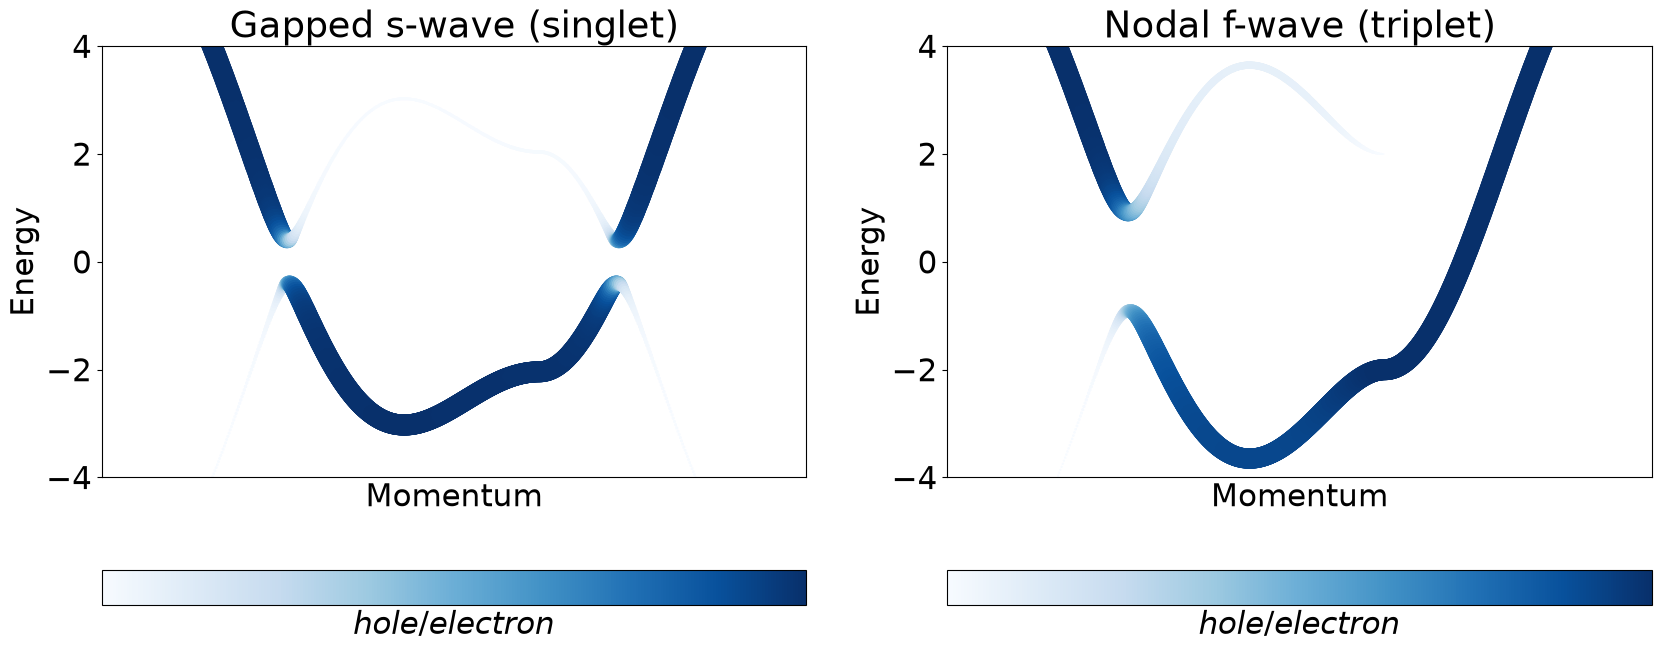

In [17]:
from pyqula import geometry
g = geometry.triangular_lattice() # generate a triangular lattice

# first s-wave
plt.subplot(1,2,1) ;  plt.title("Gapped s-wave (singlet)")
h = g.get_hamiltonian() # generate Hamiltonian
h.add_pairing(mode="swave",delta=0.4) # add swave pairing
(k,e,c) = h.get_bands(operator="electron",kpath=["G","K","M","G"]) # compute bands
plt.scatter(k,e,c=c,s=200*c,cmap="Blues") ; plt.xlabel("Momentum") 
plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-4,4]) # plot
plt.colorbar(label="$hole/electron$",ticks=[],orientation="horizontal")

# now nodal f-wave
plt.subplot(1,2,2) ;  plt.title("Nodal f-wave (triplet)")
h = g.get_hamiltonian() # generate Hamiltonian
h.add_pairing(mode="nodal_fwave",delta=0.2) # add nodal f-wave pairing
(k,e,c) = h.get_bands(operator="electron",kpath=["G","K","M","G"]) # compute bands
plt.scatter(k,e,c=c,s=200*c,cmap="Blues") ; plt.xlabel("Momentum") 
plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-4,4]) # plot
plt.colorbar(label="$hole/electron$",ticks=[],orientation="horizontal")

### Quiz
- Discuss why an f-wave order is a triplet superconducting order parameter
- Discuss in which points of the Brillouin zone the triplet order (odd order parameter) must have nodes

#### In the lab
- Nodal superconductivity has been observed in twisted graphene trilayers 
https://www.nature.com/articles/s41586-022-04715-z

## s-wave superconductivity in the presence of spin-orbit coupling (***Challenge***)
Here we look at the impact of Rashba spin-orbit coupling, and its interplay with s-wave superconductivity. Due to Kramers' theorem, a finite Rashba spin-orbit coupling is not detrimental for an s-wave superconducting state

Rashba spin-orbit coupling splits the bands in momentum space, but the splitting is opposite at $\mathbf k$ and $-\mathbf k$, so the degeneracy $E_\uparrow(\mathbf k)=E_\downarrow(-\mathbf k)$ survives, this is Kramers degeneracy, and it survives because spin-orbit coupling does not break time reversal symmetry. An s-wave order pairs precisely those two partners, $(\mathbf k,\uparrow)$ with $(-\mathbf k,\downarrow)$, and this is why the gap remains even for very large spin-orbit coupling. This is the same reason why non-magnetic disorder does not damage an s-wave superconductor, which is the content of Anderson's theorem.

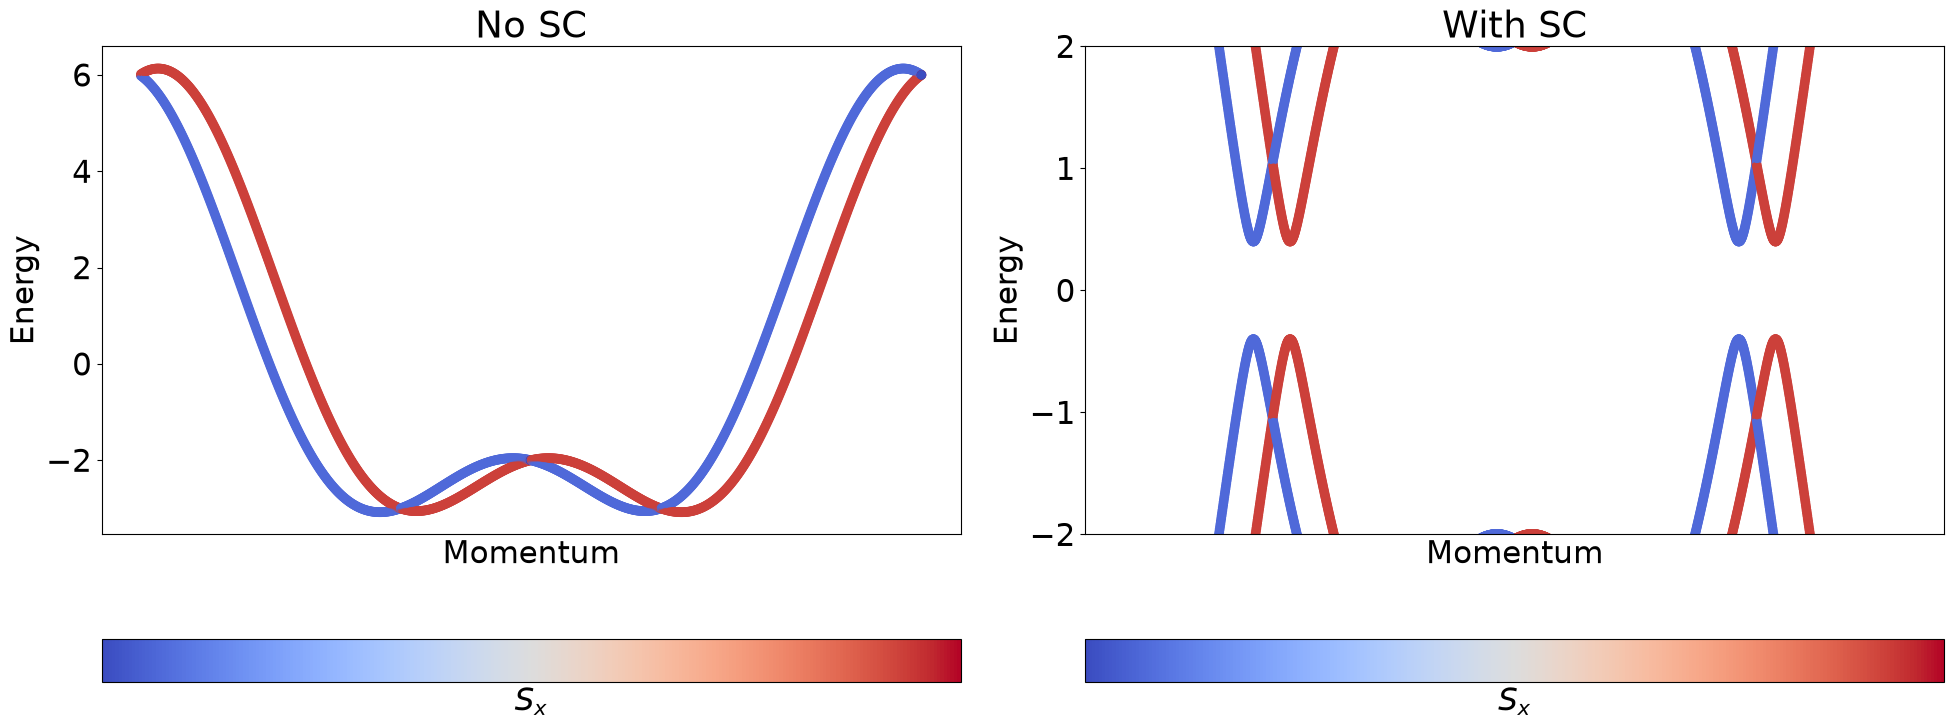

In [18]:
# first compute the bands without superconductivity
from pyqula import geometry 
g = geometry.triangular_lattice()
h = g.get_hamiltonian() # generate Hamiltonian

plt.subplot(1,2,1) ; plt.title("No SC")
h.add_rashba(0.3) # add Rashba SOC
(k,e,c) = h.get_bands(operator="sx",nk=800) # compute bands
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([])
plt.colorbar(label="$S_x$",ticks=[],orientation="horizontal")

plt.subplot(1,2,2) ; plt.title("With SC")
h.add_swave(0.4)
(k,e,c) = h.get_bands(operator="sx",nk=2000) # compute bands
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-2,2]) # plot
plt.colorbar(label="$S_x$",ticks=[],orientation="horizontal")

plt.tight_layout()

### Quiz
- Change the value of the SOC, does the superconducting gap change?
- Discuss why the SOC does not impact the superconductivity phenomenology discussed above.

## s-wave superconductivity in the presence of magnetism (***Challenge***)
Let us now see how the presence of magnetism impacts an s-wave superconducting state

Here we take a square lattice with an s-wave order and we add an exchange field $J$ of increasing strength. There is a competition between magnetism and s-wave superconductivity: if magnetism wins your system becomes a magnetic metal, and if superconductivity wins it remains a superconductor. Look at how the gap evolves as you increase $J$, and at how the value at which it closes depends on the superconducting order.

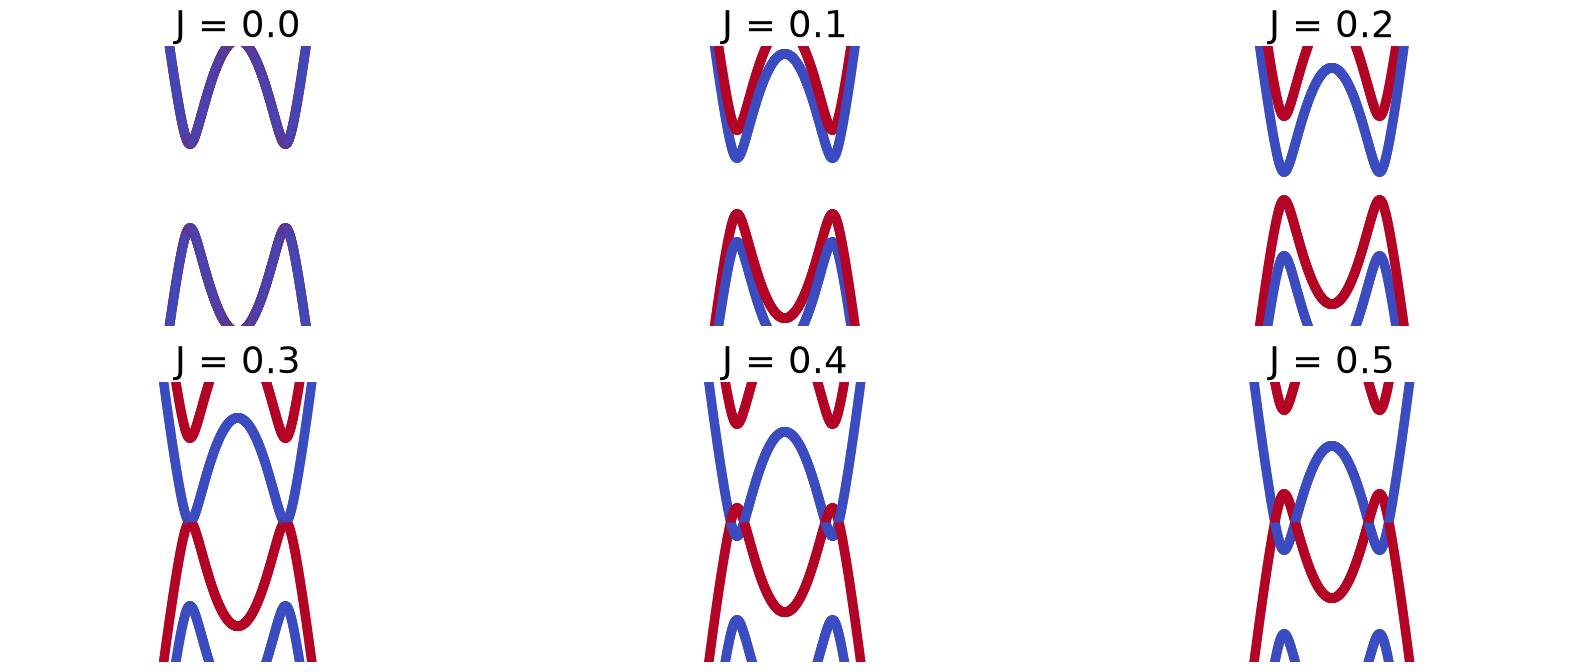

In [19]:
# plot the bands for different exchange couplings
from pyqula import geometry
Js = np.linspace(0.,0.5,6) # exchange couplings
ij = 0 # counter
for J in Js: # loop over exchange couplings
    g = geometry.square_lattice() # get the geometry
    h = g.get_hamiltonian() # get the Hamiltonian
    h.add_onsite(3.) # shift chemical potential
    h.add_zeeman([0.,0.,J]) # add exchange field
    h.add_swave(0.3) # add swave SC
    (k,e,c) = h.get_bands(nk=1000,operator="sz") # compute the bands
    plt.subplot(len(Js)//3,3,ij+1) ; ij +=1 
    plt.scatter(k,e,c=c) ; plt.axis("off") ; plt.ylim([-1.,1.]) ; plt.title("J = "+str(round(J,2))) # plot

### Quiz
- Change the value of the superconducting term. At which value of the exchange do you see the gap closing?
- Discuss why a magnetic exchange field closes the gap 

## Magnetic disorder in an s-wave superconductor (***Challenge***)
Let us now add random magnetic disorder to a superconductor, and see how that impact the superconducting gap

Here we take a supercell of a triangular lattice with s-wave superconductivity, and we add a magnetic impurity in every site with a random direction of the magnetization, for different strengths of the disorder. This is the same competition as in the previous exercise but now happening locally: each magnetic impurity breaks time reversal symmetry around it and breaks the Cooper pairs there, and this gives rise to states inside the gap. Non-magnetic disorder is a different story.

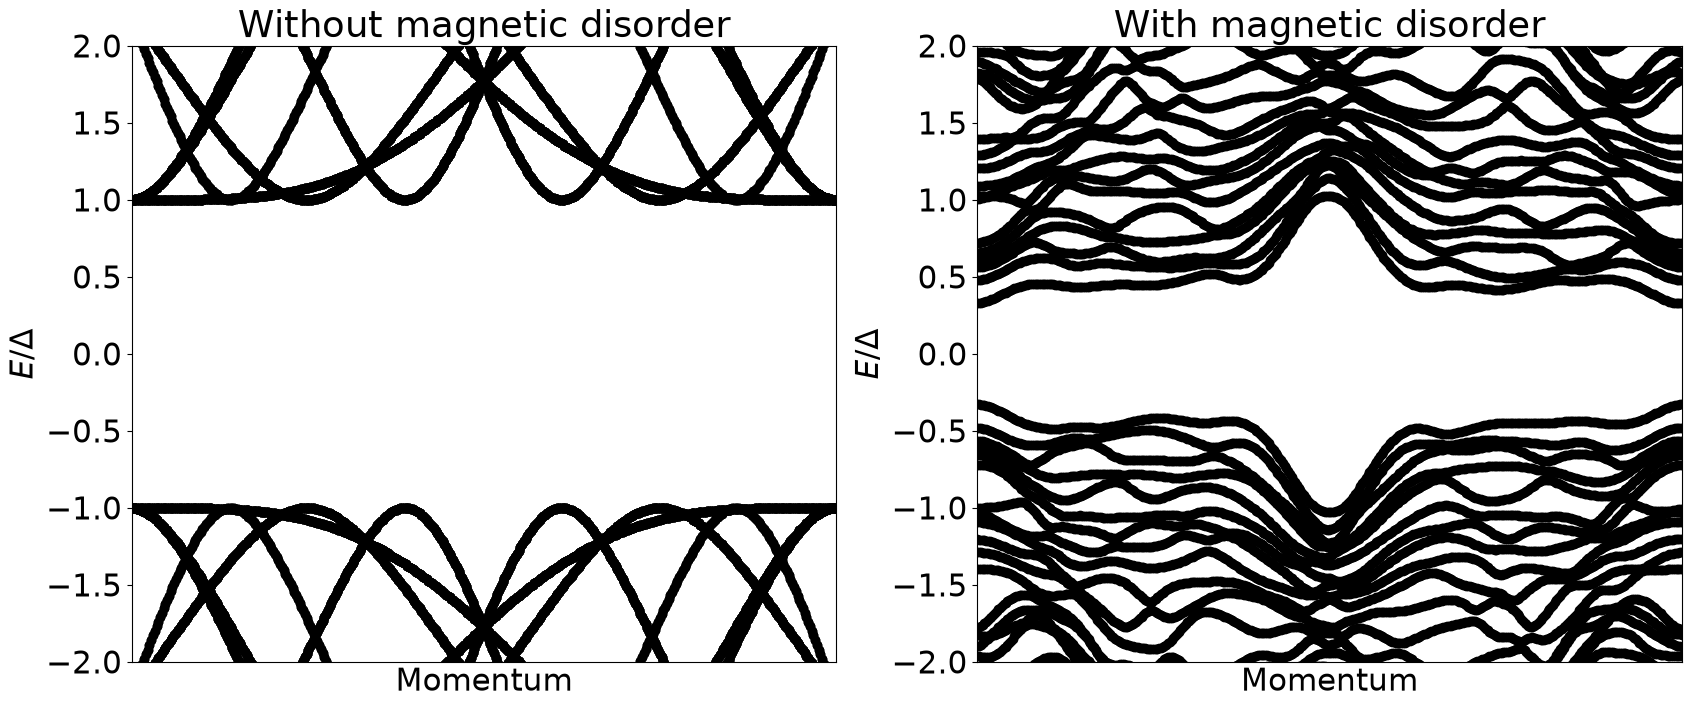

In [20]:
from pyqula import geometry, potentials
g = geometry.triangular_lattice() # take a triangular lattice
g = g.get_supercell((6,6)) # make a supercell so that we have many sites per unit cell
h = g.get_hamiltonian() # generate Hamiltonian

delta = 0.5 # superconducting order parameter
h.add_swave(delta) # add superconductivity

def plot_bands(k,e): # function to plot both bands
    plt.scatter(k,e/delta,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("$E/\\Delta$") 
    plt.xticks([]) ; plt.ylim([-2.,2.]) ; plt.xlim([min(k),max(k)]) # plot


# first without magnetic disorder
plt.subplot(1,2,1) ; plt.title("Without magnetic disorder")
(k,e) = h.get_bands() # compute bands
plot_bands(k,e)

# now with the magnetic disorder
plt.subplot(1,2,2) ; plt.title("With magnetic disorder")
h.add_exchange(lambda r: 2*delta*(np.random.random(3)-0.5)) # add local magnetic disorder
#h.add_onsite(lambda r: 2*delta*(np.random.random()-0.5)) # add local disorder
(k,e) = h.get_bands() # compute bands
plot_bands(k,e) # plot the bands

### Quiz
- Change the strength of the magnetic disorder. How does the in-gap band change?
- Replace the magnetic disorder by non-magnetic disorder (add_onsite). Discuss why the result is different from the magnetic disorder

## Artificial topological superconductivity (***Challenge***)
We will create an artificial topological superconductor by combining s-wave superconductivity, exchange field and Rashba spin-orbit coupling. For the sake of concreteness we will use a triangular lattice with first neighbor hopping.

The idea is the following: we start with a triangular lattice, we add Rashba spin-orbit coupling, which splits the bands in a momentum dependent way, then we add an exchange field, which opens up gaps in some of the crossings, and we put the chemical potential so that we cross a certain number of helical states. Once we add s-wave superconductivity on top of that, the state that we get is an effective chiral p-wave superconductor with a finite Chern number, even though the pairing that we added was conventional. This is what is called an artificial topological superconductor, and we compute the Chern number to check it.

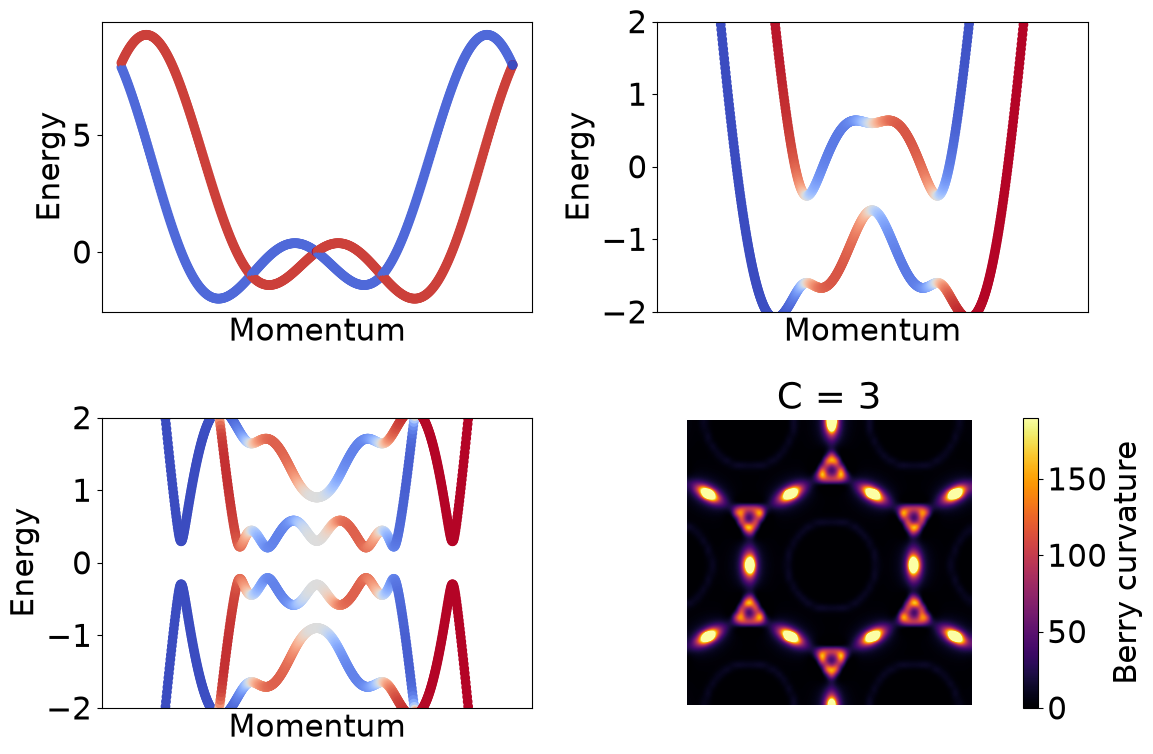

In [21]:
# Now we add Rashba spin-orbit coupling, to create a spin-momentum locking in the electronic structure
from pyqula import geometry
g = geometry.triangular_lattice() # get the geometry
h = g.get_hamiltonian() # get the Hamiltonian
h.add_rashba(1.0) # Rashba spin-orbit coupling
h.add_onsite(2.0) # shift chemical potential

plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
(k,e,c) = h.get_bands(operator="sx") # compute the bands
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) # plot

plt.subplot(2,2,2)
h.add_zeeman([0.,0.,-0.6]) # Zeeman field
(k,e,c) = h.get_bands(operator="sx",nk=800) # compute the bands
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-2.,2.]) # plot

plt.subplot(2,2,3)
h.add_swave(.3) # add superconductivity
(k,e,c) = h.get_bands(operator="sx",nk=800) # compute the bands
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-2.,2.]) # plot
#plt.colorbar(label="Berry curvature",ticks=[])

plt.subplot(2,2,4)
nk = 60 # number of kpoints
c = h.get_chern(nk=nk) # compute Chern number
# now let us compute the Berry curvature in 2D
(kx,ky,omega) = h.get_berry_curvature(nk=nk) # compute Berry curvature
plt.title("C = "+str(int(round(c))))
omega2d = np.array(omega).reshape((nk,nk)) # reshape as a 2d array
plt.imshow(omega2d,interpolation="bicubic",cmap="inferno",vmax=np.max(omega)/4.,vmin=0.) # plot
plt.axis("equal") ; plt.colorbar(label="Berry curvature") ; plt.axis("off") 

plt.tight_layout()

### Quiz
- Decrease value of the Rashba SOC. Does the splitting in momentum space become bigger or smaller?
- Discuss why an out-of plane field opens a gap in some of the previous crossings of the band structure
- Decrease value of the exchange field. Do the anticrossings become bigger or smaller?
- Discuss what can be the consequence of having a Chern number
- If you change the chemical potential, do you still get a finite Chern number? Discuss why

## Edge states of an artificial topological superconductor (***Challenge***)
Here, taking as starting point the Hamiltonian of a topological superconductor above, we will show how topological edge states appear in finite systems

We take the same triangular lattice with Rashba coupling, exchange field and s-wave superconductivity, we create a ribbon, and we compute its band structure and the local density of states at zero energy. As with the chiral p-wave superconductor before, a finite Chern number in the bulk has to show up as states crossing the gap and localized at the edges, and the number of those states is set by the Chern number.

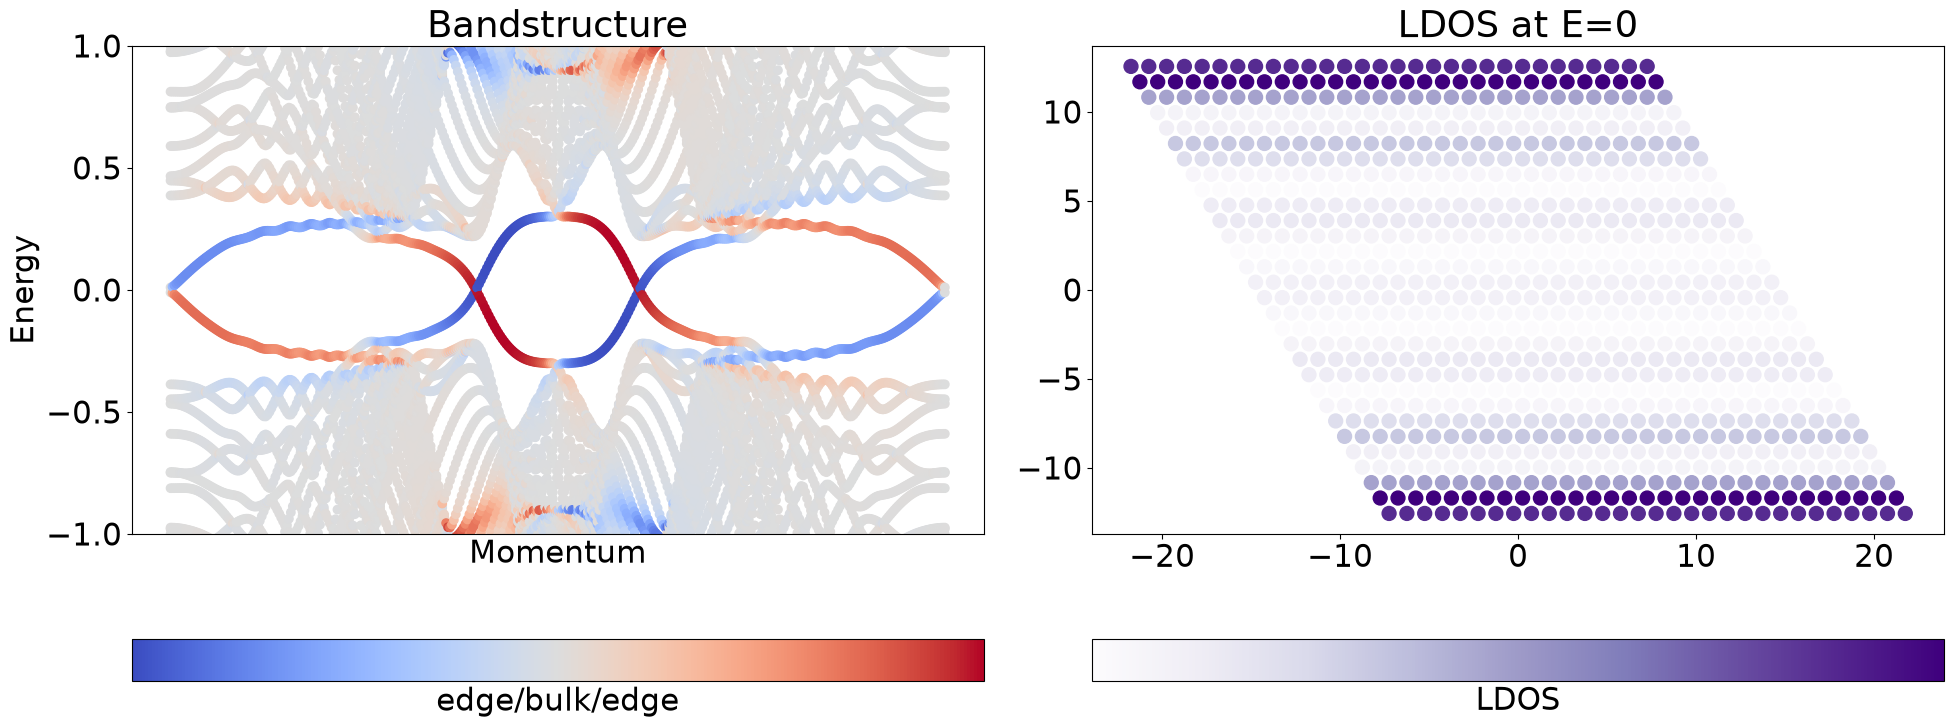

In [22]:
from pyqula import ribbon,geometry
g = geometry.triangular_lattice() # get the geometry
h = g.get_hamiltonian() # get the Hamiltonian
h.add_rashba(1.0) # Rashba spin-orbit coupling
h.add_onsite(2.0) # shift chemical potential
h.add_zeeman([0.,0.,0.6]) # Zeeman field
h.add_swave(.3) # add superconductivity

plt.subplot(1,2,1) ; plt.title("Bandstructure") # first the bands
hr = ribbon.bulk2ribbon(h,n=30) # create a ribbon from a bulk Hamiltonian
(k,e,c) = hr.get_bands(operator="yposition") # plot the bands highlighting the position
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") ; plt.xticks([]) ; plt.ylim([-1.,1.])
plt.colorbar(label="edge/bulk/edge",ticks=[],orientation="horizontal")

plt.subplot(1,2,2) ; plt.title("LDOS at E=0") # now the LDOS
(x,y,d) = hr.get_ldos(energy=0.0,nrep=30,delta=1e-2,nk=50) # compute the local density of states
plt.scatter(x,y,c=d,s=100,cmap="Purples") ; plt.axis("equal") 
plt.colorbar(label="LDOS",ticks=[],orientation="horizontal")

plt.tight_layout() # adjust subplots

### Quiz
- The localization of the edge modes depends on the topological gap. Show that for parameters yielding a small topological gap, the edge states are more delocalized
- Show that if the ribbon is not wide enough, the edge states hybridize and lead to a gap opening

#### In the lab
- Topological superconductivity has been observed in artificial NbSe2/CrBr3 heterostructures
https://www.nature.com/articles/s41586-020-2989-y

## Topological phase transition as a function of the exchange field (***Challenge***)
Above we saw that superconductivity can coexist with spin-orbit coupling. Since the superconductor at zero exchange field is trivial, a topological phase transition must occur as the exchange field is turned on. Here we will show how such a phase transition takes place

Here we keep the Rashba coupling, the chemical potential and the s-wave order fixed, and we increase the exchange field $J$ step by step. At $J=0$ we have a conventional s-wave superconductor, that is trivial, and at large $J$ we are in the artificial topological superconductor of the previous exercises. To go from one to the other the gap has to close and reopen, and the value of $J$ at which this happens is set by the competition between the Zeeman splitting and the spin-orbit splitting of the bands. Follow the gap in the plots to see where this happens.

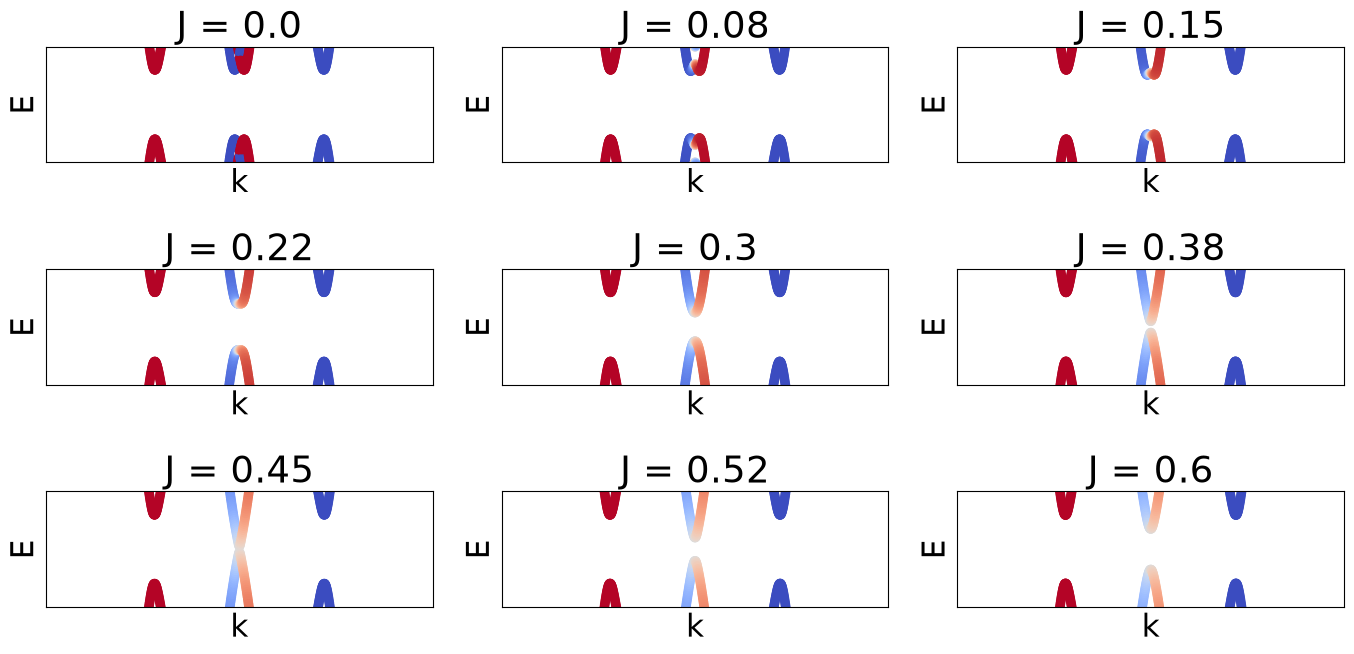

In [23]:
# plot the bands for different exchange couplings
from pyqula import geometry
Js = np.linspace(0.,0.6,9) # exchange couplings
fig = plt.figure(figsize=(14,7))
ij = 0 # counter
for J in Js: # loop over exchange couplings
    g = geometry.triangular_lattice() # get the geometry
    h = g.get_hamiltonian() # get the Hamiltonian
    h.add_onsite(-5.7) # shift chemical potential
    h.add_rashba(1.0) # add Rashba SOC
    h.add_zeeman([0.,0.,J]) # add exchange field
    h.add_swave(0.3) # add swave SC
    (k,e,c) = h.get_bands(nk=1000,operator="sx",kpath=["M1","G","M1"]) # compute the bands
    plt.subplot(len(Js)//3,3,ij+1) ; ij +=1 
    plt.scatter(k,e,c=c) ; plt.ylim([-0.5,0.5]) ; plt.title("J = "+str(round(J,2))) # plot
    plt.xticks([]) ; plt.yticks([]) ; plt.xlabel("k") ; plt.ylabel("E")

plt.tight_layout() # adjust subplots

### Quiz
- At which exchange coupling does the topological phase transition happen?
- Replace the out of plane field by an in-plane one. Can you get a topological phase?